# 02 · Construction des variables

Quatre séries de variables, testées l'une après l'autre. Les trois premières n'utilisent que les caractéristiques des lignes (apprentissage et test réunis), jamais la cible. La quatrième utilise les totaux connus, calculés hors pli.

| Série | Blocs testés | Résultat |
|---|---|---|
| 1 (exp. 07) | précision de saisie, déplacements, contexte de compétition | gardés ensemble : −0.67 kg |
| 2 (exp. 09) | contexte enrichi, divisions, historique du sportif, coefficient DOTS, identifiants | seul l'historique passe le seuil : −0.13 kg |
| 3 (exp. 10) | carrière, expérience du plateau, ajouts propres à chaque modèle | gardés : −0.20 kg |
| 4 (exp. 14) | niveau du sportif et de la compétition, à partir des totaux | moins bon, abandonné |

**Règle.** Chaque bloc est jugé sur la combinaison NNLS de LightGBM, XGBoost et CatBoost, avec les cinq plis fixes et l'early stopping interne. On le garde s'il fait gagner au moins 0.05 kg en moyenne et s'il améliore au moins 4 plis sur 5.

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : le notebook relit les résultats sauvegardés dans `artifacts/`, sur CPU, en quelques minutes. Pour refaire une expérience, mettre son bouton à `True` et choisir un runtime **T4 GPU**. Chaque modèle est sauvegardé dès qu'il est entraîné, donc une exécution interrompue reprend où elle s'était arrêtée. Un seul bouton à la fois, et redémarrer le runtime avant de passer au suivant.

In [1]:
"""Compatibilité avec les résultats existants et libellés de présentation.

Les valeurs historiques ci-dessous sont volontairement conservées : elles déterminent
les clés JSON, les noms de caches et leur ordre. Le code de calcul utilise les noms
explicites des constantes ; seules des copies destinées à l’affichage sont traduites.
"""

BLOCK_RECORDING_PRECISION = 'P'
BLOCK_TRAVEL = 'T'
BLOCK_MEET_CONTEXT = 'M'
BLOCK_EXTENDED_MEET_CONTEXT = 'M2'
BLOCK_DIVISION_CONTEXT = 'D'
BLOCK_ATHLETE_HISTORY = 'H'
BLOCK_DOTS_SCALE = 'S'
BLOCK_PROXY_IDENTIFIERS = 'C'
BLOCK_ATHLETE_CAREER = 'H2'
BLOCK_MEET_EXPERIENCE = 'E'
BLOCK_MODEL_SPECIFIC = 'PM'
BLOCK_ATHLETE_PERFORMANCE = 'AS'
BLOCK_MEET_PERFORMANCE = 'MS'
VARIANT_WEIGHT_CLASS_BASELINE = 'F0'
VARIANT_PRECISION_AND_TRAVEL = 'PT'
VARIANT_CONTEXT_COMBINED = 'ALL'
VARIANT_CONTEXT_BASELINE = 'R1'
VARIANT_HISTORY_COMBINED = 'ALL2'
VARIANT_HISTORY_BASELINE = 'R2'
VARIANT_FINAL_FEATURES = 'ALL3'
VARIANT_FINAL_BASELINE = 'R3'
VARIANT_PERFORMANCE_COMBINED = 'ALL4'
CATBOOST_DEPTH8_BASELINE = 'C1'
CATBOOST_DEPTH8_REGULARIZED = 'C2'
CATBOOST_DEPTH6_REGULARIZED = 'C3'
MODEL_LIGHTGBM = 'lgb'
MODEL_XGBOOST = 'xgb'
MODEL_CATBOOST_ABSOLUTE = 'catboost'
MODEL_LIGHTGBM_DOTS = 'lgb_rel'
MODEL_CATBOOST_DOTS = 'cb_rel'
MODEL_CATBOOST_IPF_GL = 'cb_gl'
MODEL_CATBOOST_ALLOMETRIC = 'cb_allo'
MODEL_HISTOGRAM_GRADIENT_BOOSTING = 'hgb'
MODEL_EXTRA_TREES = 'et'
MODEL_RANDOM_FOREST = 'rf'
MATCH_RESIDENCE = 'A0'
MATCH_FEDERATION = 'A1'
MATCH_EQUIPMENT = 'A2'
MATCH_WEIGHT_CLASS = 'A3'
MATCH_MEET = 'M2'
SMOOTHING_EXACT_BIRTHYEAR = 'S0_exact'
SMOOTHING_NEARBY_BIRTHYEAR = 'S1_fuzzy'
SMOOTHING_TEMPORAL = 'S2_decay'
SMOOTHING_COMBINED_LINEAR = 'S3_all_linear'
SMOOTHING_COMBINED_BOOSTING = 'S4_all_gbm'
CACHE_CONTEXT_ABLATION = 'round1'
CACHE_HISTORY_ABLATION = 'round2'
CACHE_CAREER_ABLATION = 'round3'
CACHE_PERFORMANCE_ABLATION = 'round4'
CACHE_SIX_MODEL_ENSEMBLE = 'v1_six_models'
CACHE_EXPANDED_SEED_ENSEMBLE = 'v2_more_seeds'
CACHE_FINAL_ENSEMBLE = 'v4_eight_models'
CACHE_INITIAL_ENSEMBLE = 'baseline_v1'
CACHE_TEN_FOLD_ENSEMBLE = 'baseline_v2'
ENSEMBLE_INITIAL = 'v1'
ENSEMBLE_TEN_FOLD = 'v2'
ENSEMBLE_WITH_HISTOGRAM_BOOSTING = 'v3_plus'
ENSEMBLE_FINAL = 'v4'
MODEL_CATBOOST_DEPTH8_BASELINE = 'catboost_C1'
CONFIG_PURPOSE_CONTEXT_ABLATION = 'feature round 1 (P/T/M blocks); inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_HISTORY_ABLATION = 'feature round 2 on top of 07 ALL; inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_CAREER_ABLATION = 'feature round 3 on top of 09 ALL2; inner 10% early stop, score early-stopped model on outer fold'
MODEL_CATBOOST_DEPTH8_REGULARIZED = 'catboost_C2'
MODEL_CATBOOST_DEPTH6_REGULARIZED = 'catboost_C3'
CONFIG_PURPOSE_MODEL_COMPARISON = 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold'

CACHE_CATBOOST_IPF_GL_BASELINE_STEM = 'cb_gl__R3'
CACHE_CATBOOST_IPF_GL_SEED42_STEM = 'cb_gl__s42'
MODEL_CATBOOST_PREFIX = 'cb_'
MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE = 'cb_rel_lr03'
CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE = 'final ensemble: ALL3 per-model features, 5-fold x seeds, inner 10% early stop, full refit'
SUMMARY_RESIDUAL_SMOOTHING = '+S3'
SUMMARY_FINAL_SMOOTHING = '+ S3 smoothing (cross-fitted coefficients)'
SUMMARY_FINAL_CANDIDATES = '+ HGB + cb_gl (final)'
SUBMISSION_FINAL_BASE_FILENAME = 'submission_final_v4_base.csv'
SUBMISSION_FINAL_FILENAME = 'submission_final_v4_final.csv'

LEGACY_SUMMARY_COMBINED_SMOOTHING = '+ S3 \u5e73\u6ed1\uff08\u4ea4\u53c9\u62df\u5408\uff09'
HISTORY_TEN_FOLD_MATCHING = 'v2 + twins'
HISTORY_WEIGHT_CLASS_MATCHING = '07 F0 + twins'
HISTORY_CONTEXT_REGULARIZED = '07 ALL + C2'
HISTORY_CONTEXT_REGULARIZED_MATCHING = '07 ALL + C2 + twins'
HISTORY_MODEL_STACKING = '08 stack'
HISTORY_STACKING_MATCHING = '08 + twins'
HISTORY_STACKING_RESIDUAL_SMOOTHING = '08 + twins + athlete'
HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING = 'v2 + twins + athlete'
HISTORY_FINAL_FEATURES_MATCHING = '10 ALL3 + twins'
HISTORY_EXACT_BIRTHYEAR_SMOOTHING = '10 + S0'
HISTORY_COMBINED_RESIDUAL_SMOOTHING = '10 + S3'
HISTORY_SIX_MODEL_FOLD_AVERAGE = '11 fold average'
HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE = '13 v3_plus'
HISTORY_FINAL_FEATURES_REFERENCE = '14 R3'
HISTORY_ATHLETE_PERFORMANCE = '14 AS'
HISTORY_FINAL_ENSEMBLE = '15 v4 (final)'


PRESENTATION_LABELS = {
    HISTORY_TEN_FOLD_MATCHING: 'v2 + jumelles',
    HISTORY_WEIGHT_CLASS_MATCHING: 'variables de départ + jumelles',
    HISTORY_CONTEXT_REGULARIZED: 'série 1 + CatBoost régularisé',
    HISTORY_CONTEXT_REGULARIZED_MATCHING: 'série 1 + CatBoost régularisé + jumelles',
    HISTORY_MODEL_STACKING: 'exp. 08 : plus de modèles',
    HISTORY_STACKING_MATCHING: 'exp. 08 + jumelles',
    HISTORY_STACKING_RESIDUAL_SMOOTHING: 'exp. 08 + jumelles + lissage',
    HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING: 'v2 + jumelles + lissage',
    HISTORY_FINAL_FEATURES_MATCHING: 'série 3 + jumelles',
    HISTORY_EXACT_BIRTHYEAR_SMOOTHING: 'série 3 + lissage (même année)',
    HISTORY_COMBINED_RESIDUAL_SMOOTHING: 'série 3 + lissage combiné',
    HISTORY_SIX_MODEL_FOLD_AVERAGE: 'six modèles, moyenne des plis',
    HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE: 'six modèles + HGB',
    HISTORY_FINAL_FEATURES_REFERENCE: 'référence de la série 4',
    HISTORY_ATHLETE_PERFORMANCE: 'niveau du sportif',
    HISTORY_FINAL_ENSEMBLE: 'huit modèles',
    '+ HGB + cb_gl (final, exp. 15)': '+ HGB + CatBoost IPF GL (exp. 15)',
    BLOCK_RECORDING_PRECISION: 'Précision',
    BLOCK_TRAVEL: 'Déplacements',
    BLOCK_MEET_CONTEXT: 'Contexte',
    BLOCK_EXTENDED_MEET_CONTEXT: 'Contexte enrichi',
    BLOCK_DIVISION_CONTEXT: 'Divisions',
    BLOCK_ATHLETE_HISTORY: 'Historique',
    BLOCK_DOTS_SCALE: 'Coefficient DOTS',
    BLOCK_PROXY_IDENTIFIERS: 'Identifiants',
    BLOCK_ATHLETE_CAREER: 'Carrière',
    BLOCK_MEET_EXPERIENCE: 'Expérience du plateau',
    BLOCK_MODEL_SPECIFIC: 'Ajouts par modèle',
    BLOCK_ATHLETE_PERFORMANCE: 'Niveau du sportif',
    BLOCK_MEET_PERFORMANCE: 'Niveau de la compétition',
    VARIANT_WEIGHT_CLASS_BASELINE: 'Départ',
    VARIANT_PRECISION_AND_TRAVEL: 'Précision + déplacements',
    VARIANT_CONTEXT_COMBINED: 'Série 1 complète',
    VARIANT_CONTEXT_BASELINE: 'Référence série 2',
    VARIANT_HISTORY_COMBINED: 'Série 2 retenue',
    VARIANT_HISTORY_BASELINE: 'Référence série 3',
    VARIANT_FINAL_FEATURES: 'Variables finales',
    VARIANT_FINAL_BASELINE: 'Référence série 4',
    VARIANT_PERFORMANCE_COMBINED: 'Niveaux combinés',
    CATBOOST_DEPTH8_BASELINE: 'prof. 8, L2 3',
    CATBOOST_DEPTH8_REGULARIZED: 'prof. 8, L2 10',
    CATBOOST_DEPTH6_REGULARIZED: 'prof. 6, L2 10',
    MODEL_CATBOOST_DOTS: 'CatBoost DOTS',
    MODEL_LIGHTGBM_DOTS: 'LightGBM DOTS',
    MODEL_CATBOOST_IPF_GL: 'CatBoost IPF GL',
    MODEL_CATBOOST_ALLOMETRIC: 'CatBoost allométrique',
    MODEL_LIGHTGBM: 'LightGBM',
    MODEL_XGBOOST: 'XGBoost',
    MODEL_CATBOOST_ABSOLUTE: 'CatBoost',
    MODEL_HISTOGRAM_GRADIENT_BOOSTING: 'HGB',
    MODEL_EXTRA_TREES: 'ExtraTrees',
    MODEL_RANDOM_FOREST: 'Forêt aléatoire',
    MATCH_RESIDENCE: 'Clé 1 :',
    MATCH_FEDERATION: 'Clé 2 :',
    MATCH_EQUIPMENT: 'Clé 3 :',
    MATCH_WEIGHT_CLASS: 'Clé 4 :',
    'S0': 'même année',
    'S1': 'année ±1',
    'S2': 'pondération temporelle',
    'S3': 'lissage combiné',
    'S4': 'lissage LightGBM',
    ENSEMBLE_INITIAL: 'v1',
    ENSEMBLE_TEN_FOLD: 'v2',
    ENSEMBLE_WITH_HISTOGRAM_BOOSTING: 'six modèles + HGB',
    ENSEMBLE_FINAL: 'huit modèles',
    SMOOTHING_EXACT_BIRTHYEAR: 'Même année',
    SMOOTHING_NEARBY_BIRTHYEAR: 'Année ±1',
    SMOOTHING_TEMPORAL: 'Pondération temporelle',
    SMOOTHING_COMBINED_LINEAR: 'Combinaison linéaire',
    SMOOTHING_COMBINED_BOOSTING: 'Combinaison par LightGBM',
}


def presentation_label(value):
    """Traduire un libellé d’expérience sans toucher à sa valeur de calcul."""
    if isinstance(value, tuple):
        return tuple(presentation_label(part) for part in value)
    if not isinstance(value, str):
        return value
    if '|' in value:
        return value
    if value in PRESENTATION_LABELS:
        return PRESENTATION_LABELS[value]
    import re
    if value.endswith(('.csv', '.npz', '.npy', '.json')):
        return value
    keys = [key for key in PRESENTATION_LABELS if key not in (MODEL_EXTRA_TREES, MODEL_RANDOM_FOREST)]
    pattern = r'(?<![A-Za-z0-9_])(' + '|'.join(re.escape(key) for key in sorted(keys, key=len, reverse=True)) + r')(?![A-Za-z0-9_])'
    return re.sub(pattern, lambda match: PRESENTATION_LABELS[match.group()], value)


def presentation_copy(value):
    """Traduire uniquement les libellés de synthèse, sur une copie du tableau."""
    if 'pd' in globals() and isinstance(value, (pd.DataFrame, pd.Series)):
        shown = value.copy(deep=True)
        raw_columns = set(globals().get('RAW_FEATURES', []))
        label_fields = {'model', 'variant', 'tag', 'step', 'method', 'submission',
                        'params_key', 'feature', 'source', 'experiment', 'config',
                        'Ensemble', 'Modèle', 'Expérience', 'Clé'}
        # Un extrait des données conserve toutes ses valeurs et ses catégories.
        if isinstance(shown, pd.DataFrame) and raw_columns.intersection(shown.columns):
            return shown
        if isinstance(shown.index, pd.MultiIndex):
            names = shown.index.names
            shown.index = pd.MultiIndex.from_tuples(
                [tuple(presentation_label(part) if name in label_fields else part
                       for name, part in zip(names, row)) for row in shown.index], names=names)
        elif shown.index.name in label_fields:
            shown.index = shown.index.map(presentation_label)
        if isinstance(shown, pd.DataFrame):
            for column in shown.select_dtypes(include=['object', 'string']):
                if column in label_fields:
                    shown[column] = shown[column].map(presentation_label)
            # Les colonnes de modèles ou de variantes proviennent d’un pivot nommé.
            if shown.columns.name in label_fields:
                shown.columns = shown.columns.map(presentation_label)
        elif shown.name in label_fields and (shown.dtype == object or isinstance(shown.dtype, pd.StringDtype)):
            shown = shown.map(presentation_label)
        return shown
    if isinstance(value, dict):
        return {presentation_label(key): presentation_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [presentation_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple(presentation_copy(item) for item in value)
    return presentation_label(value)


def display(*values, **kwargs):
    """Afficher des libellés explicites sans modifier les tableaux de calcul."""
    return _display(*(presentation_copy(value) for value in values), **kwargs)


def print(*values, **kwargs):
    """Présenter les résumés textuels sans modifier les objets de calcul."""
    import builtins
    return builtins.print(*(presentation_copy(value) for value in values), **kwargs)

In [2]:
TRAIN = {
    CACHE_CONTEXT_ABLATION: False,   # Exp. 07 : 6 variantes × 3 modèles × 5 plis, CatBoost et correspondances d’enregistrements (~1.5–2 h GPU)
    CACHE_HISTORY_ABLATION: False,   # Exp. 09 : deuxième série (~1.5–2 h GPU)
    CACHE_CAREER_ABLATION: False,   # Exp. 10 : troisième série et lissage (~1–1.5 h GPU)
    CACHE_PERFORMANCE_ABLATION: False,   # Exp. 14 : variables avec cible, id et cibles alternatives (~1–1.5 h GPU)
}

In [3]:
# Environnement, chemins et configuration communs aux cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # CSV sources, en lecture seule
ARTIFACTS = PROJECT_DIR / 'artifacts'           # Un sous-dossier de résultats par notebook
SEED = 42                                       # Cinq plis fixes : KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 10 % du train externe réservé à l’early stopping
MAX_ROUNDS = 20000
MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]             # Trois modèles pour les ablations, les plus rapides en premier
RUN_ONLY = None                                 # Liste de variantes à exécuter ; None = toutes
KEEP_DELTA = -0.05                              # kg : garder si ΔRMSE moyen ≤ −0.05 et amélioration sur ≥ 4/5 plis
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # Pas de bouton dans 01/05 ; 01 entraîne un petit HGB adversarial
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('Activer un seul entraînement à la fois ; redémarrer le runtime avant le suivant (variables partagées)')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """Préparer les dépendances et vérifier le GPU uniquement pour un entraînement."""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version(MODEL_CATBOOST_ABSOLUTE)
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if MODEL_CATBOOST_ABSOLUTE in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà importée ; redémarrer le runtime')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # Les autres modèles restent disponibles si cet import échoue
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version actuelle : {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('Un GPU est requis : choisir T4 GPU dans le type de runtime Colab, puis relancer')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {MODEL_CATBOOST_ABSOLUTE: catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('Versions    :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit indisponible, RealMLP / TabM seront ignorés :', PYTABKIT_ERROR)


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('Entraînements activés :', [k for k, v in TRAIN.items() if v])

Projet : performances-en-powerlifting
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


## 0. Données et plis

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} differs from the original input; check the data file')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # Independent of object / str dtype (pandas 2 and 3).
require(train.shape == (105000, 18) and test.shape == (45000, 17), 'Unexpected data shape')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), 'Unexpected column groups')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), 'Unexpected missing values')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}; validation rows per fold: {np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17); validation rows per fold: [21000, 21000, 21000, 21000, 21000]


## 1. Première série (expérience 07)

Le point de départ est l'analyse des résidus de la version v2 (RMSE hors pli 77.302). Plusieurs groupes ont un résidu moyen nettement différent de zéro :

| Groupe | Résidu moyen (kg) | Ce que ça suggère |
|---|---|---|
| Âge entier / en .5 | +2.6 / −3.6 (USAPL : +19.0 / −5.5) | la précision de la date de naissance dépend de la compétition |
| Poids entier / à deux décimales | −2.9 / +1.3 | idem pour la pesée |
| Compétition dans un autre État / dans le sien | +3.6 / −1.8 | on se déplace pour les compétitions plus relevées |
| À l'étranger / dans son pays | +1.6 / −0.5 | compétitions internationales |
| Plus petites compétitions (1/8 des lignes) | −3.6 | compétitions locales |

Une « compétition » est approchée par fédération × année × pays × État.

| Bloc | Variables |
|---|---|
| Départ | 19 colonnes : les 16 d'origine, plus `WeightClass_num`, `Is_SHW`, `BW_minus_Class` |
| Précision | `age_half` ; `bw_precision` (0 entier, 1 en .5, 2 une décimale, 3 deux décimales) ; `bw_lb_int` |
| Déplacements | `abroad`, `other_state` (NaN si la résidence est inconnue) |
| Contexte | taille de la compétition, du groupe sexe/équipement, de la fédération dans l'année ; parts de déplacements, d'âges en .5, d'équipements, d'hommes ; âge moyen |

In [5]:
both = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)

# Variables initiales et catégorie de poids: weight-class features from ensemble à dix plis et plusieurs graines
weight_class = pd.to_numeric(both['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
WEIGHT_CLASS_FEATURES = pd.DataFrame({
    'WeightClass_num': weight_class,
    'Is_SHW': both['WeightClassKg'].str.endswith('+').astype('float64'),
    'BW_minus_Class': both['BodyweightKg'] - weight_class,
})

# Précision des enregistrements: explicit indicators for recording precision, such as half-years and integers.
age2 = (both['Age'] * 2).round()
require(np.allclose(both['Age'] * 2, age2), 'Age is not a multiple of 0.5')
bw = both['BodyweightKg']
is_int = np.isclose(bw, bw.round())
is_1dec = np.isclose(bw * 10, (bw * 10).round())
is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
pounds = bw / 0.45359237
RECORDING_PRECISION_FEATURES = pd.DataFrame({
    'age_half': (age2 % 2).astype('float64'),
    'bw_precision': np.select([is_int, is_half, is_1dec], [0.0, 1.0, 2.0], default=3.0),
    'bw_lb_int': (np.abs(pounds - pounds.round()) < 0.015).astype('float64'),
})

# Déplacements: travel indicators; NaN when residence is unknown.
abroad = (both['Country'] != both['MeetCountry']).astype('float64').where(both['Country'] != 'Unknown')
state_known = ((both['State'] != 'Unknown') & (both['MeetState'] != 'Unknown')
               & (both['Country'] == both['MeetCountry']))
other_state = (both['State'] != both['MeetState']).astype('float64').where(state_known)
TRAVEL_FEATURES = pd.DataFrame({'abroad': abroad, 'other_state': other_state})

# Contexte de compétition: meet proxy = federation / year / country / state; unlabeled train+test statistics.
meet = (both['Federation'] + '|' + both['MeetYear'].astype(str) + '|'
        + both['MeetCountry'] + '|' + both['MeetState'])


def by_meet(values):
    return values.groupby(meet).transform('mean')


MEET_CONTEXT_FEATURES = pd.DataFrame({
    'meet_n': meet.map(meet.value_counts()).astype('float64'),
    'meet_sexeq_n': both.groupby([meet, both['Sex'], both['Equipment']])['Age'].transform('size').astype('float64'),
    'fed_year_n': both.groupby(['Federation', 'MeetYear'])['Age'].transform('size').astype('float64'),
    'meet_share_other_state': by_meet(other_state),
    'meet_share_abroad': by_meet(abroad),
    'meet_share_age_half': by_meet(RECORDING_PRECISION_FEATURES['age_half']),
    'meet_share_equipped': by_meet((both['Equipment'] != 'Raw').astype('float64')),
    'meet_share_male': by_meet((both['Sex'] == 'M').astype('float64')),
    'meet_mean_age': by_meet(both['Age']),
})

CONTEXT_FEATURE_BLOCKS = {BLOCK_RECORDING_PRECISION: RECORDING_PRECISION_FEATURES, BLOCK_TRAVEL: TRAVEL_FEATURES, BLOCK_MEET_CONTEXT: MEET_CONTEXT_FEATURES}
CONTEXT_VARIANTS = {VARIANT_WEIGHT_CLASS_BASELINE: [], BLOCK_RECORDING_PRECISION: [BLOCK_RECORDING_PRECISION], BLOCK_TRAVEL: [BLOCK_TRAVEL], BLOCK_MEET_CONTEXT: [BLOCK_MEET_CONTEXT], VARIANT_PRECISION_AND_TRAVEL: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL], VARIANT_CONTEXT_COMBINED: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]}
for name, frame in {VARIANT_WEIGHT_CLASS_BASELINE: WEIGHT_CLASS_FEATURES, **CONTEXT_FEATURE_BLOCKS}.items():
    require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
    require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')

_CONTEXT_FRAMES = {}


def context_feature_frames(variant, model):
    """(train, test) features. String categories for CatBoost; category dtype for LGB / XGB, using the unlabeled joint vocabulary."""
    kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
    if (variant, kind) not in _CONTEXT_FRAMES:
        frame = pd.concat([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_VARIANTS[variant]] + [both[CAT]], axis=1)
        require(frame.columns.is_unique, f'{variant} duplicate column names')
        frame[CAT] = frame[CAT].astype(str).astype(object) if kind == 'str' else frame[CAT].astype('category')
        _CONTEXT_FRAMES[(variant, kind)] = (frame.iloc[:n_train].reset_index(drop=True),
                                    frame.iloc[n_train:].reset_index(drop=True))
    return _CONTEXT_FRAMES[(variant, kind)]


print({v: context_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in CONTEXT_VARIANTS})
summary_new = pd.concat([RECORDING_PRECISION_FEATURES, TRAVEL_FEATURES, MEET_CONTEXT_FEATURES], axis=1)
display(pd.DataFrame({'train_mean': summary_new.iloc[:n_train].mean(), 'test_mean': summary_new.iloc[n_train:].mean(),
                      'nan_share': summary_new.isna().mean()}).round(4))

{'Départ': 19, 'Précision': 22, 'Déplacements': 21, 'Contexte': 28, 'Précision + déplacements': 24, 'Série 1 complète': 33}


,train_mean,test_mean,nan_share
age_half,0.4817,0.4782,0.0000
bw_precision,1.9668,1.9609,0.0000
bw_lb_int,0.0500,0.0503,0.0000
abroad,0.0824,0.0822,0.0184
other_state,0.2670,0.2724,0.6491
meet_n,63.6623,63.9177,0.0000
meet_sexeq_n,33.0578,33.1368,0.0000
fed_year_n,653.6460,656.8197,0.0000
meet_share_other_state,0.2661,0.2673,0.6219
meet_share_abroad,0.0833,0.0837,0.0004


## 2. Deuxième série (expérience 09)

On part des 33 colonnes de la première série.

| Bloc | Contenu |
|---|---|
| Contexte enrichi | diversité des États, pays et catégories ; parts de contrôles antidopage, d'équipements, de précisions de poids, de juniors et masters ; dispersion des âges, poids moyen par sexe, taille nationale |
| Divisions | taille de la division (compétition × sexe × équipement × catégorie), rang de poids et d'âge, nombre de jumelles |
| Historique du sportif | pour un sportif approché : nombre d'apparitions, années actives, temps depuis la première et jusqu'à la dernière, équipements utilisés, écart de poids |
| Coefficient DOTS | coefficient poids–sexe : total = score DOTS × coefficient |
| Identifiants | clés de compétition et de sportif données comme catégories, pour CatBoost seulement |

Clé du sportif : sexe + pays + État + fédération + année de naissance. L'année de naissance est estimée par `floor(MeetYear − Age)` et peut être fausse d'un an quand l'âge est entier.

In [6]:
_CONTEXT_FRAMES.clear()                     # Release cached feature frames from experiment 07.
CORE9 = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
sex, equipment = both['Sex'], both['Equipment']
state = both['State'].where(both['State'] != 'Unknown')
country = both['Country'].where(both['Country'] != 'Unknown')
national = both['Federation'] + '|' + both['MeetYear'].astype(str) + '|' + both['MeetCountry']


def counts(key):
    return key.map(key.value_counts()).astype('float64')


def n_distinct(values, key):
    return values.groupby(key).transform('nunique').astype('float64')


# Contexte de compétition enrichi: additional meet context; meet and by_meet come from experiment 07.
EXTENDED_MEET_CONTEXT_FEATURES = pd.DataFrame({
    'meet_n_states': n_distinct(state, meet),
    'meet_n_countries': n_distinct(country, meet),
    'meet_n_wclass': n_distinct(both['WeightClassKg'], meet),
    'meet_share_tested': by_meet((both['Tested'] == 'Yes').astype('float64')),
    'meet_share_raw': by_meet((equipment == 'Raw').astype('float64')),
    'meet_share_multi': by_meet((equipment == 'Multi-ply').astype('float64')),
    'meet_share_bw2dec': by_meet((RECORDING_PRECISION_FEATURES['bw_precision'] == 3).astype('float64')),
    'meet_share_junior': by_meet((both['Age'] < 24).astype('float64')),
    'meet_share_master': by_meet((both['Age'] >= 40).astype('float64')),
    'meet_age_std': both['Age'].groupby(meet).transform('std'),
    'meet_sex_bw_mean': both['BodyweightKg'].groupby([meet, sex]).transform('mean'),
    'nat_n': counts(national),
    'nat_n_meetstates': n_distinct(both['MeetState'], national),
    'nat_n_states': n_distinct(state, national),
})

# Effectifs et rangs des divisions: division context
division = meet + '|' + sex + '|' + equipment + '|' + both['WeightClassKg']
age_division = meet + '|' + sex + '|' + equipment + '|' + both['AgeClass']
exact_key = pd.Series(pd.util.hash_pandas_object(both[RAW_FEATURES], index=False).to_numpy())
core_key = pd.Series(pd.util.hash_pandas_object(both[CORE9], index=False).to_numpy())
DIVISION_FEATURES = pd.DataFrame({
    'div_n': counts(division),
    'div_bw_rank': both['BodyweightKg'].groupby(division).rank(pct=True),
    'div_age_rank': both['Age'].groupby(division).rank(pct=True),
    'agediv_n': counts(age_division),
    'dup_exact_n': counts(exact_key) - 1,
    'dup_core_n': counts(core_key) - 1,
})

# Historique approché du sportif: athlete proxy history from floor(MeetYear - Age); birth-year estimates may differ by one.
valid = (both['Country'] != 'Unknown').to_numpy()
birth = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int).astype(str)
athlete = sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation'] + '|' + birth
athlete0 = sex + '|' + both['Country'] + '|' + both['State'] + '|' + birth
year = both['MeetYear'].astype('float64')
ATHLETE_HISTORY_FEATURES = pd.DataFrame({
    'ath_n': counts(athlete),
    'ath_n_years': n_distinct(year, athlete),
    'ath_years_since_first': year - year.groupby(athlete).transform('min'),
    'ath_years_to_last': year.groupby(athlete).transform('max') - year,
    'ath_n_equipment': n_distinct(equipment, athlete),
    'ath_bw_delta': both['BodyweightKg'] - both['BodyweightKg'].groupby(athlete).transform('mean'),
    'ath0_n': counts(athlete0),
    'ath0_n_feds': n_distinct(both['Federation'], athlete0),
})
ATHLETE_HISTORY_FEATURES.loc[~valid] = np.nan


# Facteur DOTS: DOTS scale (TotalKg = DOTS score * dots_scale)
def dots_scale(sex_values, bw_values):
    s = np.asarray(sex_values).astype(str)
    bw = np.asarray(bw_values, dtype='float64')
    m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
    poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
    poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
    return np.where(s == 'M', poly_m, np.where(s == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


DOTS_SCALE_FEATURE = pd.DataFrame({'dots_scale': dots_scale(sex, both['BodyweightKg'])})

# Identifiants approchés: high-cardinality IDs for CatBoost ordered target statistics.
PROXY_IDENTIFIER_FEATURES = pd.DataFrame({'meet_id': meet, 'athlete_id': (athlete + '|' + equipment).where(valid, 'unknown')})

HISTORY_FEATURE_BLOCKS = {BLOCK_EXTENDED_MEET_CONTEXT: EXTENDED_MEET_CONTEXT_FEATURES, BLOCK_DIVISION_CONTEXT: DIVISION_FEATURES, BLOCK_ATHLETE_HISTORY: ATHLETE_HISTORY_FEATURES, BLOCK_DOTS_SCALE: DOTS_SCALE_FEATURE}
CATBOOST_CATEGORY_BLOCKS = {BLOCK_PROXY_IDENTIFIERS: PROXY_IDENTIFIER_FEATURES}
for name, frame in {**HISTORY_FEATURE_BLOCKS, **CATBOOST_CATEGORY_BLOCKS}.items():
    require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
for name, frame in HISTORY_FEATURE_BLOCKS.items():
    require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
require(DOTS_SCALE_FEATURE['dots_scale'].min() > 0.3, 'Invalid DOTS scale')

CONTEXT_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]
HISTORY_VARIANTS = {VARIANT_CONTEXT_BASELINE: [], BLOCK_EXTENDED_MEET_CONTEXT: [BLOCK_EXTENDED_MEET_CONTEXT], BLOCK_DIVISION_CONTEXT: [BLOCK_DIVISION_CONTEXT], BLOCK_ATHLETE_HISTORY: [BLOCK_ATHLETE_HISTORY], BLOCK_DOTS_SCALE: [BLOCK_DOTS_SCALE], BLOCK_PROXY_IDENTIFIERS: [BLOCK_PROXY_IDENTIFIERS]}
MODELS_FOR = {BLOCK_PROXY_IDENTIFIERS: [MODEL_CATBOOST_ABSOLUTE]}      # Identifiants approchés changes CatBoost only; retain Référence avec contexte for LightGBM / XGBoost in the blend.
SCREEN = [v for v in HISTORY_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_CONTEXT_BASELINE]
_HISTORY_FRAMES = {}


def models_for(variant):
    return MODELS_FOR.get(variant, MODELS)


def history_feature_frames(variant, model):
    """Retourner train, test et colonnes catégorielles : variables initiales, catégorie de poids, précision, déplacements et contexte ; les identifiants approchés sont ajoutés à CatBoost uniquement."""
    blocks = HISTORY_VARIANTS[variant]
    kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
    key = (tuple(blocks), kind)
    if key not in _HISTORY_FRAMES:
        nums = ([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_BASE_BLOCKS]
                + [HISTORY_FEATURE_BLOCKS[b] for b in blocks if b in HISTORY_FEATURE_BLOCKS])
        cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
        frame = pd.concat(nums + cats, axis=1)
        require(frame.columns.is_unique, f'{variant} duplicate column names')
        cat_cols = [c for part in cats for c in part.columns]
        if kind == 'str':
            frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
        else:
            frame[cat_cols] = frame[cat_cols].astype('category')
        _HISTORY_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                         frame.iloc[n_train:].reset_index(drop=True), cat_cols)
    return _HISTORY_FRAMES[key]


new_cols = pd.concat([EXTENDED_MEET_CONTEXT_FEATURES, DIVISION_FEATURES, ATHLETE_HISTORY_FEATURES, DOTS_SCALE_FEATURE], axis=1)
display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                      'nan_share': new_cols.isna().mean()}).round(4))
print('Cardinality of C: ', {c: int(PROXY_IDENTIFIER_FEATURES[c].nunique()) for c in PROXY_IDENTIFIER_FEATURES.columns})
print('Columns by variant (LightGBM / XGBoost): ', {v: history_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in HISTORY_VARIANTS if v != BLOCK_PROXY_IDENTIFIERS},
      '|CatBoost C: ', history_feature_frames(BLOCK_PROXY_IDENTIFIERS, MODEL_CATBOOST_ABSOLUTE)[0].shape[1])

,train_mean,test_mean,nan_share
meet_n_states,3.2039,3.2371,0.0000
meet_n_countries,2.0094,2.0170,0.0000
meet_n_wclass,10.7194,10.7360,0.0000
meet_share_tested,0.7627,0.7604,0.0000
meet_share_raw,0.6208,0.6212,0.0000
meet_share_multi,0.0234,0.0240,0.0000
meet_share_bw2dec,0.2949,0.2969,0.0000
meet_share_junior,0.4549,0.4538,0.0000
meet_share_master,0.1703,0.1714,0.0000
meet_age_std,10.0628,10.0618,0.0104


Cardinality of Identifiants:  {'meet_id': 10546, 'athlete_id': 46893}


Columns by variant (LightGBM / XGBoost):  {'Référence série 2': 33, 'Contexte enrichi': 47, 'Divisions': 39, 'Historique': 41, 'Coefficient DOTS': 34} |CatBoost C:  35


## 3. Troisième série (expérience 10)

On part des 41 colonnes obtenues en ajoutant l'historique.

| Bloc | Contenu |
|---|---|
| Carrière | plus grande compétition fréquentée, nombre d'États, compétitions à l'étranger, catégories, amplitude de poids, âge à la première apparition, apparitions par an, part de compétitions contrôlées, correspondances avec une année de naissance à ±1 |
| Expérience du plateau | pour une compétition : nombre moyen d'apparitions et d'années d'expérience des participants, part de vétérans (3 ans ou plus) et de débutants |
| Ajouts par modèle | contexte enrichi + identifiants pour CatBoost ; contexte enrichi + DOTS + divisions pour XGBoost ; rien de plus pour LightGBM |

Le dernier bloc vient de la série 2 : certains blocs aidaient un modèle sans aider les autres.

In [7]:
_HISTORY_FRAMES.clear()                    # Release cached feature frames from experiment 09.
birth_num = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int)


def fuzzy_count(prefix_key):
    """Count rows with the same prefix and birth years b-1, b, b+1."""
    exact = prefix_key + '|' + birth_num.astype(str)
    table = exact.value_counts()
    total = exact.map(table).astype('float64')
    for d in (-1, 1):
        total = total + (prefix_key + '|' + (birth_num + d).astype(str)).map(table).fillna(0)
    return total


# Carrière approchée du sportif: career features; athlete/valid and Contexte de compétition enrichi from 09, Contexte de compétition/Déplacements from 07.
bw = both['BodyweightKg']
ATHLETE_CAREER_FEATURES = pd.DataFrame({
    'ath_max_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('max'),
    'ath_mean_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('mean'),
    'ath_max_meet_n': MEET_CONTEXT_FEATURES['meet_n'].groupby(athlete).transform('max'),
    'ath_max_nat_states': EXTENDED_MEET_CONTEXT_FEATURES['nat_n_states'].groupby(athlete).transform('max'),
    'ath_ever_abroad': TRAVEL_FEATURES['abroad'].groupby(athlete).transform('max'),
    'ath_n_wclass': n_distinct(both['WeightClassKg'], athlete),
    'ath_bw_range': bw.groupby(athlete).transform('max') - bw.groupby(athlete).transform('min'),
    'ath_first_age': both['Age'].groupby(athlete).transform('min'),
    'ath_n_same_year': both.groupby([athlete, both['MeetYear']])['Age'].transform('size').astype('float64'),
    'ath_share_tested': (both['Tested'] == 'Yes').astype('float64').groupby(athlete).transform('mean'),
    'ath_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation']),
    'ath0_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State']),
})
ATHLETE_CAREER_FEATURES.loc[~valid] = np.nan

# Expérience du plateau: experience profile of a meet
experience = ATHLETE_HISTORY_FEATURES['ath_years_since_first']
MEET_EXPERIENCE_FEATURES = pd.DataFrame({
    'meet_mean_ath_n': ATHLETE_HISTORY_FEATURES['ath_n'].groupby(meet).transform('mean'),
    'meet_mean_ath_exp': experience.groupby(meet).transform('mean'),
    'meet_share_veterans': (experience >= 3).astype('float64').where(experience.notna()).groupby(meet).transform('mean'),
    'meet_share_newcomers': (ATHLETE_HISTORY_FEATURES['ath_n'] == 1).astype('float64').where(ATHLETE_HISTORY_FEATURES['ath_n'].notna()).groupby(meet).transform('mean'),
})

CAREER_FEATURE_BLOCKS = {BLOCK_ATHLETE_CAREER: ATHLETE_CAREER_FEATURES, BLOCK_MEET_EXPERIENCE: MEET_EXPERIENCE_FEATURES}
for name, frame in CAREER_FEATURE_BLOCKS.items():
    require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
    require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
NUMERIC_BLOCKS = {**CONTEXT_FEATURE_BLOCKS, **HISTORY_FEATURE_BLOCKS, **CAREER_FEATURE_BLOCKS}          # Précision des enregistrements Déplacements Contexte de compétition (07), Contexte de compétition enrichi Effectifs et rangs des divisions Historique approché du sportif Facteur DOTS (09), Carrière approchée du sportif Expérience du plateau (this round)
HISTORY_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT, BLOCK_ATHLETE_HISTORY]                          # Contexte et historique du sportif from experiment 09
MODEL_SPECIFIC_BLOCKS = {MODEL_LIGHTGBM: [], MODEL_XGBOOST: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_DOTS_SCALE, BLOCK_DIVISION_CONTEXT], MODEL_CATBOOST_ABSOLUTE: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_PROXY_IDENTIFIERS]}   # Ajouts propres à chaque modèle: blocks selected separately by model in experiment 09.
CAREER_VARIANTS = {VARIANT_HISTORY_BASELINE: [], BLOCK_ATHLETE_CAREER: [BLOCK_ATHLETE_CAREER], BLOCK_MEET_EXPERIENCE: [BLOCK_MEET_EXPERIENCE], BLOCK_MODEL_SPECIFIC: [BLOCK_MODEL_SPECIFIC]}
SCREEN3 = [v for v in CAREER_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_HISTORY_BASELINE]
_CAREER_FRAMES = {}


def feature_blocks_for_model(variant, model):
    out = list(HISTORY_BASE_BLOCKS)
    for b in CAREER_VARIANTS[variant]:
        out += MODEL_SPECIFIC_BLOCKS[model] if b == BLOCK_MODEL_SPECIFIC else [b]
    return out


def runs(model, variant):
    """Entraîner seulement si les variables diffèrent de la référence avec historique ; les ajouts propres au modèle laissent LightGBM inchangé."""
    return variant == VARIANT_HISTORY_BASELINE or feature_blocks_for_model(variant, model) != feature_blocks_for_model(VARIANT_HISTORY_BASELINE, model)


def career_feature_frames(variant, model):
    """(train, test, categorical columns)."""
    blocks = feature_blocks_for_model(variant, model)
    kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
    key = (tuple(blocks), kind)
    if key not in _CAREER_FRAMES:
        nums = [both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [NUMERIC_BLOCKS[b] for b in blocks if b in NUMERIC_BLOCKS]
        cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
        frame = pd.concat(nums + cats, axis=1)
        require(frame.columns.is_unique, f'{variant} {model} duplicate column names')
        cat_cols = [c for part in cats for c in part.columns]
        if kind == 'str':
            frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
        else:
            frame[cat_cols] = frame[cat_cols].astype('category')
        _CAREER_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                         frame.iloc[n_train:].reset_index(drop=True), cat_cols)
    return _CAREER_FRAMES[key]


new_cols = pd.concat([ATHLETE_CAREER_FEATURES, MEET_EXPERIENCE_FEATURES], axis=1)
display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                      'nan_share': new_cols.isna().mean()}).round(4))
print({f'{v}/{m}': career_feature_frames(v, m)[0].shape[1] for v in CAREER_VARIANTS for m in MODELS if runs(m, v)})

,train_mean,test_mean,nan_share
ath_max_meet_states,7.2553,7.2965,0.0184
ath_mean_meet_states,3.2682,3.2702,0.0184
ath_max_meet_n,112.4144,112.6788,0.0184
ath_max_nat_states,17.7174,17.7553,0.0184
ath_ever_abroad,0.1208,0.1206,0.0184
ath_n_wclass,6.3779,6.4201,0.0184
ath_bw_range,48.6372,49.1032,0.0184
ath_first_age,24.1705,24.0925,0.0184
ath_n_same_year,4.9418,4.9522,0.0184
ath_share_tested,0.7628,0.7612,0.0184


{'Référence série 3/LightGBM': 41, 'Référence série 3/XGBoost': 41, 'Référence série 3/CatBoost': 41, 'Carrière/LightGBM': 53, 'Carrière/XGBoost': 53, 'Carrière/CatBoost': 53, 'Expérience du plateau/LightGBM': 45, 'Expérience du plateau/XGBoost': 45, 'Expérience du plateau/CatBoost': 45, 'Ajouts par modèle/XGBoost': 62, 'Ajouts par modèle/CatBoost': 57}


## 4. Variables tirées des résultats (expérience 14)

Les variables sans cible n'apportent presque plus rien. Le lissage du notebook 04 utilise déjà les autres totaux d'un sportif, mais après la prédiction. Ici on essaie de les donner directement au modèle :

- niveau du sportif : nombre, moyenne, maximum et moyenne pondérée dans le temps de ses autres scores DOTS, écarts d'année et de poids ;
- niveau de la compétition : force relative des autres participants.

Pour éviter la fuite, la partie d'apprentissage de chaque pli est redécoupée en 5 : une ligne ne voit que les totaux des autres sous-plis. La validation et le test utilisent toute la partie d'apprentissage.

## 5. Ablations

Dans les tableaux : `mean_delta` est la variation moyenne de RMSE (négative = mieux), `folds_better` le nombre de plis améliorés, `keep` indique si le seuil est atteint. Sur les figures, la barre est la moyenne, les points sont les plis, le trait pointillé le seuil de −0.05.

In [8]:
# Lecture des summary_*.csv et prédictions de plis ; aucun entraînement
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'Fichier absent : {path.relative_to(PROJECT_DIR)} ; synchroniser artifacts/ depuis Drive ou activer l’entraînement associé')
        return None
    table = pd.read_csv(path, index_col=index_col)
    # Traduire les anciens libellés en mémoire, sans modifier les caches CSV.
    label_map = {
        LEGACY_SUMMARY_COMBINED_SMOOTHING: '+ lissage combiné des résidus (coefficients croisés)',
        '+ \u53cc\u80de\u80ce\uff08\u4ea4\u53c9\u62df\u5408\uff09': '+ jumeaux (cross-fitting)',
        '+\u53cc\u80de\u80ce': '+matched',
        '08 \u4e94\u6298\u5806\u53e0\uff08global_nnls\uff09': '08 stacking, cinq plis (global_nnls)',
        '3 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '3 refits',
        '5 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '5 refits',
        '8 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '8 refits',
        'v2\uff0810 \u6298 \xd7 \u79cd\u5b50\uff0cNNLS\uff09': 'v2 (10 plis × graines, NNLS)',
        '\u500d\u6570': 'ratio',
        '\u540c\u4e00\u56fd\u5bb6': 'Même pays',
        '\u540c\u4e00\u573a\u6bd4\u8d5b': 'Même compétition',
        '\u540c\u4e00\u6bd4\u8d5b\u5e74\u4efd': 'Même année de compétition',
        '\u540c\u4e00\u8054\u76df': 'Même fédération',
        '\u6309 id \u6392\u5e8f': 'sorted_by_id',
        '\u6765\u6e90': 'source',
        '\u76f8\u90bb\u4e24\u884c': 'adjacent_rows',
        '\u878d\u5408\uff08\u5d4c\u5957\uff09': 'Ensemble (RMSE locale)',
        '\u968f\u673a\u987a\u5e8f': 'random_order',
    }
    table = table.rename(columns=label_map, index=label_map)
    for column in table.select_dtypes(include=['object', 'string']):
        table[column] = table[column].map(lambda value: label_map.get(value, value))
    return table


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """Comparaison appariée : barre = ΔRMSE moyen, points = plis, pointillé = seuil −0.05."""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([presentation_label(value) for value in rows.index.tolist()])
    ax.set_xlabel(f'Écart de RMSE par rapport à {presentation_label(baseline)} (kg) ; barres : moyenne, points : plis')
    ax.set_title(presentation_label(title))
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """Charger OOF et test moyen des cinq plis ; retourner None si un pli manque."""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

### 5.1 Première série (expérience 07)

LightGBM (CPU), XGBoost et CatBoost (GPU) gardent les paramètres de la version v2. Le même entraînement sert aussi à tester la régularisation de CatBoost (notebook 03) et la correction des lignes jumelles.

In [9]:
if TRAIN[CACHE_CONTEXT_ABLATION]:
    ensure_training_env()
    # Précision, déplacements et contexte de compétition ; ancien dossier : artifacts/feature_round1_v1
    OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / CACHE_CONTEXT_ABLATION
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    RUN_PARAM_CHECK = True                 # CatBoost profondeur 8, régularisation renforcée / profondeur 6, régularisation renforcée sur les meilleures variables
    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = {
        CATBOOST_DEPTH8_BASELINE: dict(learning_rate=0.05, depth=8, l2_leaf_reg=3.0, random_strength=1.0, bagging_temperature=1.0,
                   border_count=128),                                    # = ensemble à dix plis et plusieurs graines
        CATBOOST_DEPTH8_REGULARIZED: dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                   border_count=128),                                    # Stronger L2 regularization and row subsampling
        CATBOOST_DEPTH6_REGULARIZED: dict(learning_rate=0.05, depth=6, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                   border_count=128),                                    # Shallower trees
    }
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300}


    def fit_predict(model, key, Xa, ya, Xs, ys, Xv, Xt, rounds=MAX_ROUNDS):
        """Fit on (Xa, ya), stop on (Xs, ys); return (outer predictions, test predictions, best iteration)."""
        if model == MODEL_LIGHTGBM:
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=SEED, n_jobs=-1, **LGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], callbacks=[lgb.early_stopping(PATIENCE[MODEL_LIGHTGBM], verbose=False)])
            best = int(m.best_iteration_ or rounds)
            return m.predict(Xv, num_iteration=best), m.predict(Xt, num_iteration=best), best
        if model == MODEL_XGBOOST:
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=SEED, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            best = int(m.best_iteration) + 1
            return (m.predict(Xv, iteration_range=(0, best)), m.predict(Xt, iteration_range=(0, best)), best)
        if model == MODEL_CATBOOST_ABSOLUTE:
            cats = [c for c in Xa.columns if c in CAT]
            m = catboost.CatBoostRegressor(iterations=rounds, loss_function='RMSE', eval_metric='RMSE',
                                           od_type='Iter', od_wait=PATIENCE[MODEL_CATBOOST_ABSOLUTE], random_seed=SEED,
                                           verbose=0, task_type='GPU', devices='0', allow_writing_files=False,
                                           **CB_PARAMS[key])
            m.fit(catboost.Pool(Xa, ya, cat_features=cats), eval_set=catboost.Pool(Xs, ys, cat_features=cats),
                  use_best_model=True)
            best = int(m.get_best_iteration()) + 1
            return m.predict(Xv), m.predict(Xt), best
        raise ValueError(model)


    def tag_of(model, key):
        return f'{MODEL_CATBOOST_ABSOLUTE}_{key}' if model == MODEL_CATBOOST_ABSOLUTE else model


    # Smoke check each model/variant with 30 iterations on 3,000 rows.
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    checks = [(m, v, CATBOOST_DEPTH8_BASELINE) for v in CONTEXT_VARIANTS for m in MODELS] + [(MODEL_CATBOOST_ABSOLUTE, VARIANT_WEIGHT_CLASS_BASELINE, CATBOOST_DEPTH8_REGULARIZED), (MODEL_CATBOOST_ABSOLUTE, VARIANT_WEIGHT_CLASS_BASELINE, CATBOOST_DEPTH6_REGULARIZED)]
    failed = {}
    for model, variant, key in checks:
        Xtr, Xte = context_feature_frames(variant, model)
        try:
            p_val, p_test, _ = fit_predict(model, key, Xtr.iloc[pa], y[pa], Xtr.iloc[ps], y[ps], Xtr.iloc[pv],
                                           Xte.iloc[:500], rounds=30)
            require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
            require(len(p_val) == len(pv) and len(p_test) == 500, 'Prediction length mismatch')
            print(f'Smoke check passed: {tag_of(model, key):12s} {variant:4s}({Xtr.shape[1]} columns)RMSE@30 iterations {rmse(y[pv], p_val):.1f}')
        except Exception as exc:
            failed[(model, variant, key)] = repr(exc)
            print(f'Smoke check failed, skipping: {tag_of(model, key)} {variant} → {exc!r}')
    require(not any(v == VARIANT_WEIGHT_CLASS_BASELINE and k == CATBOOST_DEPTH8_BASELINE for (_, v, k) in failed), 'F0 smoke check failed; check the environment')


    CONFIG = {'purpose': CONFIG_PURPOSE_CONTEXT_ABLATION,
              'seed': SEED, 'n_folds': N_FOLDS, 'inner_stop_fraction': INNER_STOP_FRACTION,
              'variants': CONTEXT_VARIANTS, 'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} contains results from another configuration; use a new EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def spec_of(model, variant, key):
        Xtr, _ = context_feature_frames(variant, model)
        params = {MODEL_LIGHTGBM: LGB_PARAMS, MODEL_XGBOOST: XGB_PARAMS, MODEL_CATBOOST_ABSOLUTE: CB_PARAMS[key]}[model]
        return {'model': model, 'variant': variant, 'params_key': key, 'columns': list(Xtr.columns),
                'params': dict(params), 'patience': PATIENCE[model]}


    def run_one(model, variant, key, fold):
        stem = f'{tag_of(model, key)}__{variant}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        spec = spec_of(model, variant, key)
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{stem} definition changed; use a new EXPERIMENT_ID or variant name')
            return saved, 'cache'
        Xtr, Xte = context_feature_frames(variant, model)
        fit_idx = np.flatnonzero(FOLD_IDS != fold)
        valid_idx = np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)
        started = time.perf_counter()
        p_val, p_test, best = fit_predict(model, key, Xtr.iloc[inner_fit], y[inner_fit], Xtr.iloc[inner_stop],
                                          y[inner_stop], Xtr.iloc[valid_idx], Xte)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        np.savez(npz_path, valid_idx=valid_idx, val=np.asarray(p_val, dtype='float64'),
                 test=np.asarray(p_test, dtype='float64'))
        result = {'tag': tag_of(model, key), 'variant': variant, 'fold': fold, 'spec': spec,
                  'n_features': int(Xtr.shape[1]), 'best_iteration': best,
                  'hit_limit': bool(best >= MAX_ROUNDS - PATIENCE[model]),
                  'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started,
                  'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(result, ensure_ascii=False, indent=1), encoding='utf-8')
        return result, f'{result["seconds"]:.0f}s'


    selected = [v for v in CONTEXT_VARIANTS if RUN_ONLY is None or v in RUN_ONLY]
    for fold in range(1, N_FOLDS + 1):
        fold_started = time.perf_counter()
        for model in MODELS:
            for variant in selected:
                if (model, variant, CATBOOST_DEPTH8_BASELINE) in failed:
                    continue
                result, how = run_one(model, variant, CATBOOST_DEPTH8_BASELINE, fold)
                print(f'fold {fold}  {tag_of(model, CATBOOST_DEPTH8_BASELINE):12s} {variant:4s}  RMSE {result["rmse"]:.3f}  '
                      f'best iteration {result["best_iteration"]:5d}  ({how})')
        print(f'—— fold {fold} finished; elapsed {(time.perf_counter() - fold_started) / 60:.1f} min')


    def load_results():
        rows = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))]
        require(rows, 'No completed results')
        return pd.DataFrame(rows)


    def load_oof(tag, variant):
        """Return (OOF, fold-averaged test predictions) when all five folds exist, else (None, None)."""
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = OUTPUT_DIR / f'{tag}__{variant}__fold{fold}.npz'
            if not path.is_file():
                return None, None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{tag} {variant} has incomplete OOF predictions')
        return oof, test_pred


    def fold_rmse(pred):
        return pd.Series({k: rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)})


    def paired_table(preds, base=VARIANT_WEIGHT_CLASS_BASELINE):
        """preds maps variants to OOF predictions; compare with base on paired folds."""
        require(base in preds, f'Missing baseline {base}')
        base_folds = fold_rmse(preds[base])
        rows = []
        for name, pred in preds.items():
            delta = fold_rmse(pred) - base_folds
            rows.append({'variant': name, 'oof_rmse': rmse(y, pred), 'mean_delta': delta.mean(),
                         'folds_better': int((delta < 0).sum()), **{f'd_fold{k}': v for k, v in delta.items()}})
        table = pd.DataFrame(rows).set_index('variant')
        table['keep'] = (table['mean_delta'] <= KEEP_DELTA) & (table['folds_better'] >= 4)
        table.loc[base, 'keep'] = False
        return table.sort_values('oof_rmse')


    results = load_results()
    SINGLE, TESTS = {}, {}
    for tag in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_DEPTH8_BASELINE]:
        preds = {}
        for variant in CONTEXT_VARIANTS:
            oof, test_pred = load_oof(tag, variant)
            if oof is not None:
                preds[variant], TESTS[(tag, variant)] = oof, test_pred
        if VARIANT_WEIGHT_CLASS_BASELINE in preds:
            SINGLE[tag] = paired_table(preds)
            part = results[results['tag'] == tag].groupby('variant')
            SINGLE[tag]['mean_best_iter'] = part['best_iteration'].mean()
            SINGLE[tag]['minutes'] = part['seconds'].sum() / 60
            print(f'\n=== {tag}')
            display(SINGLE[tag].round(3))

    BLENDS = {}
    for variant in CONTEXT_VARIANTS:
        if all((tag, variant) in TESTS for tag in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_DEPTH8_BASELINE]):
            P_oof = np.column_stack([load_oof(tag, variant)[0] for tag in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_DEPTH8_BASELINE]])
            P_test = np.column_stack([TESTS[(tag, variant)] for tag in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_DEPTH8_BASELINE]])
            w, _ = nnls(P_oof, y)
            BLENDS[variant] = {'oof': P_oof @ w, 'test': P_test @ w, 'weights': w.round(3).tolist()}
    require(VARIANT_WEIGHT_CLASS_BASELINE in BLENDS, 'F0 is incomplete for the three base models')
    blend_table = paired_table({v: b['oof'] for v, b in BLENDS.items()})
    blend_table['weights_lgb_xgb_cb'] = [str(BLENDS[v]['weights']) for v in blend_table.index]
    print('\n=== Three-model NNLS blend')
    display(blend_table.round(3))
    BEST = blend_table.index[0]
    print(f'Best OOF blend: {BEST}; retained variants: {blend_table.index[blend_table["keep"]].tolist() or "none"}')

    pd.concat({tag: t for tag, t in SINGLE.items()}, names=['model']).to_csv(OUTPUT_DIR / 'summary_single.csv')
    blend_table.to_csv(OUTPUT_DIR / 'summary_blend.csv')


    def residual_table(pred):
        res = y - pred
        groups = {
            'age_half': RECORDING_PRECISION_FEATURES['age_half'].iloc[:n_train].to_numpy(),
            'bw_precision': RECORDING_PRECISION_FEATURES['bw_precision'].iloc[:n_train].to_numpy(),
            'other_state(-1=unknown)': TRAVEL_FEATURES['other_state'].iloc[:n_train].fillna(-1).to_numpy(),
            'abroad(-1=unknown)': TRAVEL_FEATURES['abroad'].iloc[:n_train].fillna(-1).to_numpy(),
            'meet_n octiles': pd.qcut(MEET_CONTEXT_FEATURES['meet_n'].iloc[:n_train], 8, labels=False, duplicates='drop').to_numpy(),
        }
        frames = []
        for name, key in groups.items():
            g = pd.DataFrame({'k': key, 'r': res}).groupby('k')['r'].agg(['size', 'mean'])
            g.index = pd.MultiIndex.from_product([[name], g.index], names=['signal', 'level'])
            frames.append(g)
        return pd.concat(frames)


    check = residual_table(BLENDS[VARIANT_WEIGHT_CLASS_BASELINE]['oof']).rename(columns={'mean': VARIANT_WEIGHT_CLASS_BASELINE})
    check[BEST] = residual_table(BLENDS[BEST]['oof'])['mean']
    display(check.round(2))


    if RUN_PARAM_CHECK:
        for fold in range(1, N_FOLDS + 1):
            for key in [CATBOOST_DEPTH8_REGULARIZED, CATBOOST_DEPTH6_REGULARIZED]:
                if (MODEL_CATBOOST_ABSOLUTE, VARIANT_WEIGHT_CLASS_BASELINE, key) in failed:
                    continue
                result, how = run_one(MODEL_CATBOOST_ABSOLUTE, BEST, key, fold)
                print(f'fold {fold}  catboost_{key}  {BEST:4s}  RMSE {result["rmse"]:.3f}  '
                      f'best iteration {result["best_iteration"]:5d}  ({how})')
        preds = {}
        for key in [CATBOOST_DEPTH8_BASELINE, CATBOOST_DEPTH8_REGULARIZED, CATBOOST_DEPTH6_REGULARIZED]:
            oof, test_pred = load_oof(f'{MODEL_CATBOOST_ABSOLUTE}_{key}', BEST)
            if oof is not None:
                preds[key], TESTS[(f'{MODEL_CATBOOST_ABSOLUTE}_{key}', BEST)] = oof, test_pred
        param_table = paired_table(preds, base=CATBOOST_DEPTH8_BASELINE)
        display(param_table.round(3))
        param_table.to_csv(OUTPUT_DIR / 'summary_catboost_params.csv')
        BEST_CB = param_table.index[0] if param_table.loc[param_table.index[0], 'keep'] else CATBOOST_DEPTH8_BASELINE
    else:
        BEST_CB = CATBOOST_DEPTH8_BASELINE
    tags = [MODEL_LIGHTGBM, MODEL_XGBOOST, f'{MODEL_CATBOOST_ABSOLUTE}_{BEST_CB}']
    P_oof = np.column_stack([load_oof(tag, BEST)[0] for tag in tags])
    P_test = np.column_stack([TESTS[(tag, BEST)] for tag in tags])
    w, _ = nnls(P_oof, y)
    FINAL = {'name': f'{BEST}_blend3_{BEST_CB}', 'oof': P_oof @ w, 'test': P_test @ w}
    print(f'Final blend: features {BEST}, CatBoost {BEST_CB}, weights {dict(zip(tags, w.round(3)))}, '
          f'OOF RMSE {rmse(y, FINAL["oof"]):.3f}(F0 blend {rmse(y, BLENDS[VARIANT_WEIGHT_CLASS_BASELINE]["oof"]):.3f})')


    CORE = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                       # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                        # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(train_keys_exact, train_keys_core, query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(train_keys_exact, query_exact)
        n_co, m_co = matching_group_statistics(train_keys_core, query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / np.sum(d * d), 0, 1)) if mask.any() else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    ex_tr, co_tr = row_keys(train, RAW_FEATURES), row_keys(train, CORE)
    ex_te, co_te = row_keys(test, RAW_FEATURES), row_keys(test, CORE)
    LEVEL, MATE = matching_record_statistics(ex_tr, co_tr)
    T_LEVEL, T_MATE = matching_record_statistics(ex_tr, co_tr, ex_te, co_te)
    half = (co_tr % 2).astype(int)

    twin_rows, exports = [], {'F0_blend3': BLENDS[VARIANT_WEIGHT_CLASS_BASELINE], FINAL['name']: FINAL}
    for name, item in exports.items():
        oof = item['oof']
        alphas = {lv: fit_alpha(LEVEL == lv, oof, MATE) for lv in ['exact', 'core']}
        crossfit = oof.copy()
        for h in (0, 1):
            a = {lv: fit_alpha((half != h) & (LEVEL == lv), oof, MATE) for lv in ['exact', 'core']}
            crossfit[half == h] = apply_matching_correction(oof[half == h], MATE[half == h], LEVEL[half == h], a)
        test_fixed = apply_matching_correction(item['test'], T_MATE, T_LEVEL, alphas)
        twin_rows.append({'name': name, 'oof_rmse': rmse(y, oof), 'oof_rmse_twinfix_crossfit': rmse(y, crossfit),
                          'alpha_exact': alphas['exact'], 'alpha_core': alphas['core'],
                          'test_rows_exact': int((T_LEVEL == 'exact').sum()), 'test_rows_core': int((T_LEVEL == 'core').sum())})
        for suffix, pred in [('', item['test']), ('_twinfix', test_fixed)]:
            path = OUTPUT_DIR / f'submission_{name}{suffix}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
    twin_table = pd.DataFrame(twin_rows).set_index('name')
    display(twin_table.round(3))
    twin_table.to_csv(OUTPUT_DIR / 'summary_twins.csv')
    np.save(OUTPUT_DIR / 'oof_F0_blend3.npy', BLENDS[VARIANT_WEIGHT_CLASS_BASELINE]['oof'])
    np.save(OUTPUT_DIR / f'oof_{FINAL["name"]}.npy', FINAL['oof'])
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN[CACHE_CONTEXT_ABLATION] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN[CACHE_CONTEXT_ABLATION] = False) : lecture des résultats dans artifacts/.


RMSE OOF par modèle, cinq plis (kg) :


model,catboost_C1,LightGBM,XGBoost
variant,,,
Départ,78.824,78.579,79.323
Déplacements,78.763,78.533,79.251
Précision,78.557,78.293,78.958
Précision + déplacements,78.500,78.237,78.868
Contexte,78.349,78.254,78.955
Série 1 complète,78.065,77.923,78.806


Ensemble NNLS à trois modèles, critère principal :


,oof_rmse,mean_delta,folds_better,keep,weights_lgb_xgb_cb
variant,,,,,
Série 1 complète,77.283,-0.673,5,True,"[0.314, 0.242, 0.444]"
Contexte,77.594,-0.362,5,True,"[0.29, 0.263, 0.448]"
Précision + déplacements,77.622,-0.334,5,True,"[0.326, 0.265, 0.409]"
Précision,77.631,-0.326,5,True,"[0.326, 0.261, 0.414]"
Déplacements,77.912,-0.044,4,False,"[0.35, 0.23, 0.42]"
Départ,77.956,0.000,0,False,"[0.352, 0.23, 0.418]"


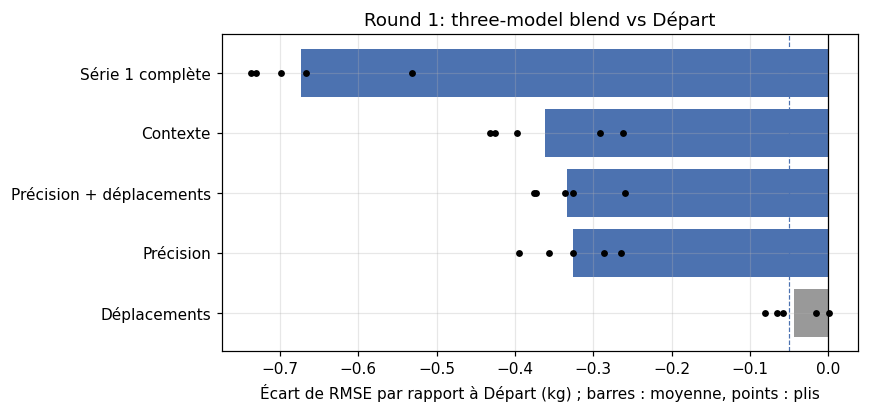

Jumeaux : alpha ajusté par cross-fitting en deux groupes core :


,oof_rmse,oof_rmse_twinfix_crossfit,alpha_exact,alpha_core,test_rows_exact,test_rows_core
name,,,,,,
F0_blend3,77.956,77.701,0.866,0.57,465,54
ALL_blend3_C2,77.210,76.966,0.864,0.54,465,54


In [10]:
def show_round1():
    directory = ARTIFACTS / '02_feature_engineering' / CACHE_CONTEXT_ABLATION
    single = read_summary(directory / 'summary_single.csv', index_col=[0, 1])
    if single is not None:
        print('RMSE OOF par modèle, cinq plis (kg) :')
        display(single['oof_rmse'].unstack(0).reindex([VARIANT_WEIGHT_CLASS_BASELINE, BLOCK_TRAVEL, BLOCK_RECORDING_PRECISION, VARIANT_PRECISION_AND_TRAVEL, BLOCK_MEET_CONTEXT, VARIANT_CONTEXT_COMBINED]).round(3))
    blend = read_summary(directory / 'summary_blend.csv')
    print('Ensemble NNLS à trois modèles, critère principal :')
    show(blend, ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'weights_lgb_xgb_cb'])
    plot_fold_deltas(blend, VARIANT_WEIGHT_CLASS_BASELINE, 'Round 1: three-model blend vs F0')
    print('Jumeaux : alpha ajusté par cross-fitting en deux groupes core :')
    show(read_summary(directory / 'summary_twins.csv'))


show_round1()

La précision fait gagner 0.33 kg et le contexte 0.36 kg, sur les 5 plis à chaque fois. Les déplacements seuls ne gagnent que 0.04 kg, sous le seuil, mais leurs colonnes servent à calculer le contexte et on les garde. **Les trois blocs ensemble gagnent 0.67 kg sur les 5 plis.** La correction des jumelles ajoute environ 0.25 kg.

Au score public : 77.947 avec les variables de départ, 77.158 avec les trois blocs et le CatBoost régularisé (les deux avec correction des jumelles).

### 5.2 Deuxième série (expérience 09)

CatBoost utilise maintenant les paramètres choisis dans le notebook 03 (L2 10, Bernoulli 0.8).

In [11]:
if TRAIN[CACHE_HISTORY_ABLATION]:
    ensure_training_env()
    # Historique approché du sportif ; ancien dossier : artifacts/feature_round2_v1
    OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / CACHE_HISTORY_ABLATION
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)                                   # profondeur 8, régularisation renforcée from experiment 07
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300}


    def fit_predict(model, Xa, ya, Xs, ys, Xv, Xt, cat_cols, rounds=MAX_ROUNDS):
        """Fit on (Xa, ya), stop on (Xs, ys); return (outer predictions, test predictions, best iteration)."""
        if model == MODEL_LIGHTGBM:
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=SEED, n_jobs=-1, **LGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], callbacks=[lgb.early_stopping(PATIENCE[MODEL_LIGHTGBM], verbose=False)])
            best = int(m.best_iteration_ or rounds)
            return m.predict(Xv, num_iteration=best), m.predict(Xt, num_iteration=best), best
        if model == MODEL_XGBOOST:
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=SEED, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            best = int(m.best_iteration) + 1
            return m.predict(Xv, iteration_range=(0, best)), m.predict(Xt, iteration_range=(0, best)), best
        if model == MODEL_CATBOOST_ABSOLUTE:
            m = catboost.CatBoostRegressor(iterations=rounds, loss_function='RMSE', eval_metric='RMSE',
                                           od_type='Iter', od_wait=PATIENCE[MODEL_CATBOOST_ABSOLUTE], random_seed=SEED,
                                           verbose=0, task_type='GPU', devices='0', allow_writing_files=False,
                                           **CB_PARAMS)
            m.fit(catboost.Pool(Xa, ya, cat_features=cat_cols), eval_set=catboost.Pool(Xs, ys, cat_features=cat_cols),
                  use_best_model=True)
            best = int(m.get_best_iteration()) + 1
            return m.predict(Xv), m.predict(Xt), best
        raise ValueError(model)


    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for variant in SCREEN:
        for model in models_for(variant):
            Xtr, Xte, cat_cols = history_feature_frames(variant, model)
            try:
                p_val, p_test, _ = fit_predict(model, Xtr.iloc[pa], y[pa], Xtr.iloc[ps], y[ps], Xtr.iloc[pv],
                                               Xte.iloc[:500], cat_cols, rounds=30)
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
                require(len(p_val) == len(pv) and len(p_test) == 500, 'Prediction length mismatch')
                print(f'Smoke check passed: {model:8s} {variant:3s}({Xtr.shape[1]} columns)RMSE@30 iterations {rmse(y[pv], p_val):.1f}')
            except Exception as exc:
                failed[(model, variant)] = repr(exc)
                print(f'Smoke check failed, skipping: {model} {variant} → {exc!r}')
    require(not any(v == VARIANT_CONTEXT_BASELINE for (_, v) in failed), 'Échec du contrôle de la référence avec contexte ; vérifier l’environnement')


    CONFIG = {'purpose': CONFIG_PURPOSE_HISTORY_ABLATION,
              'seed': SEED, 'n_folds': N_FOLDS, 'inner_stop_fraction': INNER_STOP_FRACTION,
              'r1_blocks': CONTEXT_BASE_BLOCKS, 'screen_blocks': {k: v for k, v in HISTORY_VARIANTS.items()},
              'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} contains results from another configuration; use a new EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def spec_of(model, variant):
        Xtr, _, cat_cols = history_feature_frames(variant, model)
        params = {MODEL_LIGHTGBM: LGB_PARAMS, MODEL_XGBOOST: XGB_PARAMS, MODEL_CATBOOST_ABSOLUTE: CB_PARAMS}[model]
        return {'model': model, 'variant': variant, 'blocks': list(HISTORY_VARIANTS[variant]),
                'columns': list(Xtr.columns), 'cat_cols': list(cat_cols), 'params': dict(params),
                'patience': PATIENCE[model]}


    def run_one(model, variant, fold):
        stem = f'{model}__{variant}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        spec = spec_of(model, variant)
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{stem} definition changed; use a new EXPERIMENT_ID or variant name')
            return saved, 'cache'
        Xtr, Xte, cat_cols = history_feature_frames(variant, model)
        fit_idx = np.flatnonzero(FOLD_IDS != fold)
        valid_idx = np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 07
        started = time.perf_counter()
        p_val, p_test, best = fit_predict(model, Xtr.iloc[inner_fit], y[inner_fit], Xtr.iloc[inner_stop],
                                          y[inner_stop], Xtr.iloc[valid_idx], Xte, cat_cols)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        np.savez(npz_path, valid_idx=valid_idx, val=np.asarray(p_val, dtype='float64'),
                 test=np.asarray(p_test, dtype='float64'))
        result = {'model': model, 'variant': variant, 'fold': fold, 'spec': spec, 'n_features': int(Xtr.shape[1]),
                  'best_iteration': best, 'hit_limit': bool(best >= MAX_ROUNDS - PATIENCE[model]),
                  'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started,
                  'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(result, ensure_ascii=False, indent=1), encoding='utf-8')
        return result, f'{result["seconds"]:.0f}s'


    def run_variants(variants):
        for fold in range(1, N_FOLDS + 1):
            fold_started = time.perf_counter()
            for model in MODELS:
                for variant in variants:
                    if model not in models_for(variant) or (model, variant) in failed:
                        continue
                    result, how = run_one(model, variant, fold)
                    print(f'fold {fold}  {model:8s} {variant:4s}  RMSE {result["rmse"]:.3f}  '
                          f'best iteration {result["best_iteration"]:5d}  ({how})')
            print(f'—— fold {fold} finished; elapsed {(time.perf_counter() - fold_started) / 60:.1f} min')


    run_variants(SCREEN)


    def load_oof(model, variant):
        """Return (OOF, fold-averaged test predictions) when all five folds exist, else None."""
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = OUTPUT_DIR / f'{model}__{variant}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{model} {variant} has incomplete OOF predictions')
        return oof, test_pred


    def fold_rmse(pred):
        return pd.Series({k: rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)})


    def paired_table(preds, base=VARIANT_CONTEXT_BASELINE):
        require(base in preds, f'Missing baseline {base}')
        base_folds = fold_rmse(preds[base])
        rows = []
        for name, pred in preds.items():
            delta = fold_rmse(pred) - base_folds
            rows.append({'variant': name, 'oof_rmse': rmse(y, pred), 'mean_delta': delta.mean(),
                         'folds_better': int((delta < 0).sum()), **{f'd_fold{k}': v for k, v in delta.items()}})
        table = pd.DataFrame(rows).set_index('variant')
        table['keep'] = (table['mean_delta'] <= KEEP_DELTA) & (table['folds_better'] >= 4)
        table.loc[base, 'keep'] = False
        return table.sort_values('oof_rmse')


    def blend_variant(variant):
        """NNLS à trois modèles ; réutiliser la référence avec contexte pour les modèles non modifiés."""
        loaded = []
        for model in MODELS:
            item = load_oof(model, variant if model in models_for(variant) else VARIANT_CONTEXT_BASELINE)
            if item is None:
                return None
            loaded.append(item)
        P_oof = np.column_stack([o for o, _ in loaded])
        P_test = np.column_stack([t for _, t in loaded])
        w, _ = nnls(P_oof, y)
        return {'oof': P_oof @ w, 'test': P_test @ w, 'weights': [round(float(v), 3) for v in w]}


    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))])
    for model in MODELS:
        preds = {}
        for variant in HISTORY_VARIANTS:
            item = load_oof(model, variant) if model in models_for(variant) else None
            if item is not None:
                preds[variant] = item[0]
        if VARIANT_CONTEXT_BASELINE in preds:
            table = paired_table(preds)
            part = results[results['model'] == model].groupby('variant')
            table['mean_best_iter'] = part['best_iteration'].mean()
            table['minutes'] = part['seconds'].sum() / 60
            print(f'\n=== {model}')
            display(table.round(3))
            table.to_csv(OUTPUT_DIR / f'summary_single_{model}.csv')

    BLENDS = {}
    for variant in HISTORY_VARIANTS:
        item = blend_variant(variant)
        if item is not None:
            BLENDS[variant] = item
    require(VARIANT_CONTEXT_BASELINE in BLENDS, 'Les résultats de la référence avec contexte sont incomplets pour les trois modèles')
    blend_table = paired_table({v: b['oof'] for v, b in BLENDS.items()})
    blend_table['weights_lgb_xgb_cb'] = [str(BLENDS[v]['weights']) for v in blend_table.index]
    print('\n=== Three-model NNLS blend')
    display(blend_table.round(3))
    blend_table.to_csv(OUTPUT_DIR / 'summary_blend_screen.csv')

    KEPT = [v for v in [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_DIVISION_CONTEXT, BLOCK_ATHLETE_HISTORY, BLOCK_DOTS_SCALE, BLOCK_PROXY_IDENTIFIERS] if v in blend_table.index and bool(blend_table.loc[v, 'keep'])]
    HISTORY_VARIANTS[VARIANT_HISTORY_COMBINED] = KEPT
    MODELS_FOR[VARIANT_HISTORY_COMBINED] = [MODEL_CATBOOST_ABSOLUTE] if KEPT and all(b in CATBOOST_CATEGORY_BLOCKS for b in KEPT) else MODELS
    print('Retained blocks: ', KEPT or 'none', '→ ALL2 =', [VARIANT_CONTEXT_BASELINE] + KEPT)


    if KEPT:
        for model in models_for(VARIANT_HISTORY_COMBINED):
            Xtr, Xte, cat_cols = history_feature_frames(VARIANT_HISTORY_COMBINED, model)
            p_val, p_test, _ = fit_predict(model, Xtr.iloc[pa], y[pa], Xtr.iloc[ps], y[ps], Xtr.iloc[pv],
                                           Xte.iloc[:500], cat_cols, rounds=30)          # Contexte et historique du sportif smoke check
            require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'ALL2 {model} Smoke check failed')
        run_variants([VARIANT_HISTORY_COMBINED])
        BLENDS[VARIANT_HISTORY_COMBINED] = blend_variant(VARIANT_HISTORY_COMBINED)
        final_table = paired_table({v: BLENDS[v]['oof'] for v in [VARIANT_CONTEXT_BASELINE] + KEPT + [VARIANT_HISTORY_COMBINED]})
        display(final_table.round(3))
        final_table.to_csv(OUTPUT_DIR / 'summary_blend_all2.csv')
        FINAL = VARIANT_HISTORY_COMBINED
    else:
        print('Aucun nouveau bloc ne satisfait la règle de sélection ; conserver la référence avec contexte.')
        FINAL = VARIANT_CONTEXT_BASELINE

    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / np.sum(d * d), 0, 1)) if mask.any() else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    half = (row_keys(train, CORE) % 2).astype(int)
    twin_rows = []
    for name in [VARIANT_CONTEXT_BASELINE, FINAL] if FINAL != VARIANT_CONTEXT_BASELINE else [VARIANT_CONTEXT_BASELINE]:
        oof, test_pred = BLENDS[name]['oof'], BLENDS[name]['test']
        alphas = {lv: fit_alpha(LEVEL == lv, oof, MATE) for lv in ['exact', 'core']}
        crossfit = oof.copy()
        for h in (0, 1):
            a = {lv: fit_alpha((half != h) & (LEVEL == lv), oof, MATE) for lv in ['exact', 'core']}
            crossfit[half == h] = apply_matching_correction(oof[half == h], MATE[half == h], LEVEL[half == h], a)
        fixed = apply_matching_correction(test_pred, T_MATE, T_LEVEL, alphas)
        twin_rows.append({'name': name, 'oof_rmse': rmse(y, oof), 'oof_rmse_twinfix_crossfit': rmse(y, crossfit),
                          'alpha_exact': alphas['exact'], 'alpha_core': alphas['core']})
        for suffix, pred in [('', test_pred), ('_twinfix', fixed)]:
            path = OUTPUT_DIR / f'submission_{name}_blend3{suffix}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
        np.save(OUTPUT_DIR / f'oof_{name}_blend3.npy', oof)
    twin_table = pd.DataFrame(twin_rows).set_index('name')
    display(twin_table.round(3))
    twin_table.to_csv(OUTPUT_DIR / 'summary_twins.csv')


    def bucket(values, edges, labels):
        return pd.cut(values, edges, labels=labels, right=False).astype(str)


    groups = {
        'age_half': RECORDING_PRECISION_FEATURES['age_half'].iloc[:n_train].to_numpy(),
        'bw_precision': RECORDING_PRECISION_FEATURES['bw_precision'].iloc[:n_train].to_numpy(),
        'meet_n octiles': pd.qcut(MEET_CONTEXT_FEATURES['meet_n'].iloc[:n_train], 8, labels=False, duplicates='drop').to_numpy(),
        'meet_n_states': bucket(EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].iloc[:n_train], [0, 1, 2, 5, 10, 1000], ['0', '1', '2-4', '5-9', '10+']),
        'ath_n': bucket(ATHLETE_HISTORY_FEATURES['ath_n'].iloc[:n_train].fillna(-1), [-1, 0, 2, 3, 6, 1e9], ['unknown', '1', '2', '3-5', '6+']),
        'ath_years_since_first': bucket(ATHLETE_HISTORY_FEATURES['ath_years_since_first'].iloc[:n_train].fillna(-1), [-1, 0, 1, 2, 5, 100],
                                        ['unknown', '0', '1', '2-4', '5+']),
        'dup_exact_n>0': (DIVISION_FEATURES['dup_exact_n'].iloc[:n_train] > 0).to_numpy(),
        'div_n': bucket(DIVISION_FEATURES['div_n'].iloc[:n_train], [1, 2, 4, 8, 1e9], ['1', '2-3', '4-7', '8+']),
        'Sex×Equipment': (train['Sex'] + '|' + train['Equipment']).to_numpy(),
        'Tested': train['Tested'].to_numpy(),
        'MeetYear interval': bucket(train['MeetYear'], [1900, 2000, 2010, 2015, 2020, 2030],
                              ['<2000', '2000s', '2010-14', '2015-19', '2020+']),
    }
    frames = []
    for name in [VARIANT_CONTEXT_BASELINE, FINAL] if FINAL != VARIANT_CONTEXT_BASELINE else [VARIANT_CONTEXT_BASELINE]:
        res = y - BLENDS[name]['oof']
        rows = []
        for g, key in groups.items():
            part = pd.DataFrame({'k': key, 'r': res}).groupby('k')['r'].agg(['size', 'mean'])
            part.index = pd.MultiIndex.from_product([[g], part.index.astype(str)], names=['signal', 'level'])
            rows.append(part)
        frames.append(pd.concat(rows).rename(columns={'mean': name}))
    diag = pd.concat(frames, axis=1)
    diag = diag.loc[:, ~diag.columns.duplicated()]
    display(diag.round(2))
    diag.to_csv(OUTPUT_DIR / 'diagnostics_residuals.csv')
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN[CACHE_HISTORY_ABLATION] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN[CACHE_HISTORY_ABLATION] = False) : lecture des résultats dans artifacts/.


ΔRMSE moyen par rapport à la référence avec contexte (kg ; négatif = mieux ; identifiants approchés pour CatBoost seul) :


,lgb,xgb,catboost
variant,,,
Contexte enrichi,0.071,-0.062,-0.065
Divisions,0.062,-0.079,0.115
Historique,-0.050,-0.243,-0.060
Coefficient DOTS,0.094,-0.086,0.051
Identifiants,NaN,NaN,-0.120


Ensemble NNLS à trois modèles :


,oof_rmse,mean_delta,folds_better,keep,weights_lgb_xgb_cb
variant,,,,,
Historique,77.081,-0.127,5,True,"[0.263, 0.252, 0.485]"
Identifiants,77.161,-0.047,5,False,"[0.255, 0.226, 0.52]"
Référence série 2,77.208,0.000,0,False,"[0.275, 0.233, 0.493]"
Contexte enrichi,77.212,0.003,2,False,"[0.248, 0.234, 0.518]"
Coefficient DOTS,77.260,0.052,0,False,"[0.263, 0.245, 0.492]"
Divisions,77.263,0.055,0,False,"[0.261, 0.262, 0.477]"


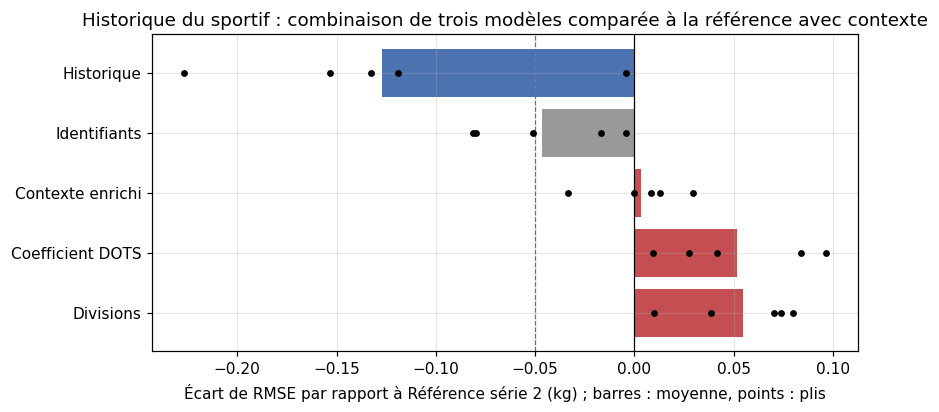

Blocs retenus dans Série 2 retenue :


,oof_rmse,mean_delta,folds_better,keep
variant,,,,
Série 2 retenue,77.077,-0.131,5,True
Historique,77.081,-0.127,5,True
Référence série 2,77.208,0.000,0,False


In [12]:
def show_round2():
    directory = ARTIFACTS / '02_feature_engineering' / CACHE_HISTORY_ABLATION
    singles = {m: read_summary(directory / f'summary_single_{m}.csv') for m in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]}
    singles = {m: t for m, t in singles.items() if t is not None}
    if singles:
        print('ΔRMSE moyen par rapport à la référence avec contexte (kg ; négatif = mieux ; identifiants approchés pour CatBoost seul) :')
        display(pd.DataFrame({m: t['mean_delta'] for m, t in singles.items()})
                .reindex([BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_DIVISION_CONTEXT, BLOCK_ATHLETE_HISTORY, BLOCK_DOTS_SCALE, BLOCK_PROXY_IDENTIFIERS]).round(3))
    screen = read_summary(directory / 'summary_blend_screen.csv')
    print('Ensemble NNLS à trois modèles :')
    show(screen, ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'weights_lgb_xgb_cb'])
    plot_fold_deltas(screen, VARIANT_CONTEXT_BASELINE, 'Historique du sportif : combinaison de trois modèles comparée à la référence avec contexte')
    print('Blocs retenus dans ALL2 :')
    show(read_summary(directory / 'summary_blend_all2.csv'), ['oof_rmse', 'mean_delta', 'folds_better', 'keep'])


show_round2()

**Seul l'historique du sportif passe le seuil : −0.13 kg sur les 5 plis.** Les identifiants aident CatBoost (−0.12) mais presque pas la combinaison (−0.05). Le contexte enrichi aide CatBoost et XGBoost (−0.06) et gêne LightGBM (+0.07). Les divisions et le coefficient DOTS n'aident que XGBoost. D'où l'idée de donner à chaque modèle ses propres ajouts dans la série suivante.

### 5.3 Troisième série (expérience 10)

Les variantes de lissage essayées pendant cette expérience sont dans le notebook 05.

In [13]:
if TRAIN[CACHE_CAREER_ABLATION]:
    ensure_training_env()
    # Carrière du sportif et ajouts propres aux modèles ; ancien dossier : artifacts/feature_round3_v1
    OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / CACHE_CAREER_ABLATION
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)                                   # profondeur 8, régularisation renforcée from experiment 07
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300}


    def fit_predict(model, Xa, ya, Xs, ys, Xv, Xt, cat_cols, rounds=MAX_ROUNDS):
        """Fit on (Xa, ya), stop on (Xs, ys); return (outer predictions, test predictions, best iteration)."""
        if model == MODEL_LIGHTGBM:
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=SEED, n_jobs=-1, **LGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], callbacks=[lgb.early_stopping(PATIENCE[MODEL_LIGHTGBM], verbose=False)])
            best = int(m.best_iteration_ or rounds)
            return m.predict(Xv, num_iteration=best), m.predict(Xt, num_iteration=best), best
        if model == MODEL_XGBOOST:
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=SEED, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            best = int(m.best_iteration) + 1
            return m.predict(Xv, iteration_range=(0, best)), m.predict(Xt, iteration_range=(0, best)), best
        if model == MODEL_CATBOOST_ABSOLUTE:
            m = catboost.CatBoostRegressor(iterations=rounds, loss_function='RMSE', eval_metric='RMSE',
                                           od_type='Iter', od_wait=PATIENCE[MODEL_CATBOOST_ABSOLUTE], random_seed=SEED,
                                           verbose=0, task_type='GPU', devices='0', allow_writing_files=False,
                                           **CB_PARAMS)
            m.fit(catboost.Pool(Xa, ya, cat_features=cat_cols), eval_set=catboost.Pool(Xs, ys, cat_features=cat_cols),
                  use_best_model=True)
            best = int(m.get_best_iteration()) + 1
            return m.predict(Xv), m.predict(Xt), best
        raise ValueError(model)



    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for variant in SCREEN3:
        for model in MODELS:
            if not runs(model, variant):
                continue
            Xtr, Xte, cat_cols = career_feature_frames(variant, model)
            try:
                p_val, p_test, _ = fit_predict(model, Xtr.iloc[pa], y[pa], Xtr.iloc[ps], y[ps], Xtr.iloc[pv],
                                               Xte.iloc[:500], cat_cols, rounds=30)
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
                require(len(p_val) == len(pv) and len(p_test) == 500, 'Prediction length mismatch')
                print(f'Smoke check passed: {model:8s} {variant:3s}({Xtr.shape[1]} columns)RMSE@30 iterations {rmse(y[pv], p_val):.1f}')
            except Exception as exc:
                failed[(model, variant)] = repr(exc)
                print(f'Smoke check failed, skipping: {model} {variant} → {exc!r}')
    require(not any(v == VARIANT_HISTORY_BASELINE for (_, v) in failed), 'Échec du contrôle de la référence avec historique ; vérifier l’environnement')


    CONFIG = {'purpose': CONFIG_PURPOSE_CAREER_ABLATION,
              'seed': SEED, 'n_folds': N_FOLDS, 'inner_stop_fraction': INNER_STOP_FRACTION,
              'r2_blocks': HISTORY_BASE_BLOCKS, 'extras': MODEL_SPECIFIC_BLOCKS, 'screen': CAREER_VARIANTS, 'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} contains results from another configuration; use a new EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def spec_of(model, variant):
        Xtr, _, cat_cols = career_feature_frames(variant, model)
        params = {MODEL_LIGHTGBM: LGB_PARAMS, MODEL_XGBOOST: XGB_PARAMS, MODEL_CATBOOST_ABSOLUTE: CB_PARAMS}[model]
        return {'model': model, 'variant': variant, 'blocks': feature_blocks_for_model(variant, model),
                'columns': list(Xtr.columns), 'cat_cols': list(cat_cols), 'params': dict(params),
                'patience': PATIENCE[model]}


    def run_one(model, variant, fold):
        stem = f'{model}__{variant}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        spec = spec_of(model, variant)
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{stem} definition changed; use a new EXPERIMENT_ID or variant name')
            return saved, 'cache'
        Xtr, Xte, cat_cols = career_feature_frames(variant, model)
        fit_idx = np.flatnonzero(FOLD_IDS != fold)
        valid_idx = np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 07
        started = time.perf_counter()
        p_val, p_test, best = fit_predict(model, Xtr.iloc[inner_fit], y[inner_fit], Xtr.iloc[inner_stop],
                                          y[inner_stop], Xtr.iloc[valid_idx], Xte, cat_cols)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        np.savez(npz_path, valid_idx=valid_idx, val=np.asarray(p_val, dtype='float64'),
                 test=np.asarray(p_test, dtype='float64'))
        result = {'model': model, 'variant': variant, 'fold': fold, 'spec': spec, 'n_features': int(Xtr.shape[1]),
                  'best_iteration': best, 'hit_limit': bool(best >= MAX_ROUNDS - PATIENCE[model]),
                  'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started,
                  'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(result, ensure_ascii=False, indent=1), encoding='utf-8')
        return result, f'{result["seconds"]:.0f}s'


    def run_variants(variants):
        for fold in range(1, N_FOLDS + 1):
            fold_started = time.perf_counter()
            for model in MODELS:
                for variant in variants:
                    if not runs(model, variant) or (model, variant) in failed:
                        continue
                    result, how = run_one(model, variant, fold)
                    print(f'fold {fold}  {model:8s} {variant:4s}  RMSE {result["rmse"]:.3f}  '
                          f'best iteration {result["best_iteration"]:5d}  ({how})')
            print(f'—— fold {fold} finished; elapsed {(time.perf_counter() - fold_started) / 60:.1f} min')


    run_variants(SCREEN3)


    def load_oof(model, variant):
        """Return (OOF, fold-averaged test predictions) when all five folds exist, else None."""
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = OUTPUT_DIR / f'{model}__{variant}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{model} {variant} has incomplete OOF predictions')
        return oof, test_pred


    def fold_rmse(pred):
        return pd.Series({k: rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)})


    def paired_table(preds, base=VARIANT_HISTORY_BASELINE):
        require(base in preds, f'Missing baseline {base}')
        base_folds = fold_rmse(preds[base])
        rows = []
        for name, pred in preds.items():
            delta = fold_rmse(pred) - base_folds
            rows.append({'variant': name, 'oof_rmse': rmse(y, pred), 'mean_delta': delta.mean(),
                         'folds_better': int((delta < 0).sum()), **{f'd_fold{k}': v for k, v in delta.items()}})
        table = pd.DataFrame(rows).set_index('variant')
        table['keep'] = (table['mean_delta'] <= KEEP_DELTA) & (table['folds_better'] >= 4)
        table.loc[base, 'keep'] = False
        return table.sort_values('oof_rmse')


    def blend_variant(variant):
        """NNLS à trois modèles ; réutiliser la référence avec historique pour les modèles non modifiés."""
        loaded = []
        for model in MODELS:
            item = load_oof(model, variant if runs(model, variant) else VARIANT_HISTORY_BASELINE)
            if item is None:
                return None
            loaded.append(item)
        P_oof = np.column_stack([o for o, _ in loaded])
        P_test = np.column_stack([t for _, t in loaded])
        w, _ = nnls(P_oof, y)
        return {'oof': P_oof @ w, 'test': P_test @ w, 'weights': [round(float(v), 3) for v in w]}


    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))])
    for model in MODELS:
        preds = {}
        for variant in CAREER_VARIANTS:
            item = load_oof(model, variant) if runs(model, variant) else None
            if item is not None:
                preds[variant] = item[0]
        if VARIANT_HISTORY_BASELINE in preds:
            table = paired_table(preds)
            part = results[results['model'] == model].groupby('variant')
            table['mean_best_iter'] = part['best_iteration'].mean()
            table['minutes'] = part['seconds'].sum() / 60
            print(f'\n=== {model}')
            display(table.round(3))
            table.to_csv(OUTPUT_DIR / f'summary_single_{model}.csv')

    BLENDS = {}
    for variant in CAREER_VARIANTS:
        item = blend_variant(variant)
        if item is not None:
            BLENDS[variant] = item
    require(VARIANT_HISTORY_BASELINE in BLENDS, 'Les résultats de la référence avec historique sont incomplets pour les trois modèles')
    blend_table = paired_table({v: b['oof'] for v, b in BLENDS.items()})
    blend_table['weights_lgb_xgb_cb'] = [str(BLENDS[v]['weights']) for v in blend_table.index]
    print('\n=== Three-model NNLS blend')
    display(blend_table.round(3))
    blend_table.to_csv(OUTPUT_DIR / 'summary_blend_screen.csv')

    KEPT = [v for v in [BLOCK_ATHLETE_CAREER, BLOCK_MEET_EXPERIENCE, BLOCK_MODEL_SPECIFIC] if v in blend_table.index and bool(blend_table.loc[v, 'keep'])]
    CAREER_VARIANTS[VARIANT_FINAL_FEATURES] = KEPT
    print('Retained blocks: ', KEPT or 'none', '→ Variables finales = référence avec historique +', KEPT)


    if KEPT:
        for model in MODELS:
            if runs(model, VARIANT_FINAL_FEATURES):
                Xtr, Xte, cat_cols = career_feature_frames(VARIANT_FINAL_FEATURES, model)
                p_val, p_test, _ = fit_predict(model, Xtr.iloc[pa], y[pa], Xtr.iloc[ps], y[ps], Xtr.iloc[pv],
                                               Xte.iloc[:500], cat_cols, rounds=30)          # Variables finales par modèle smoke check
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'ALL3 {model} Smoke check failed')
        run_variants([VARIANT_FINAL_FEATURES])
        BLENDS[VARIANT_FINAL_FEATURES] = blend_variant(VARIANT_FINAL_FEATURES)
        final_table = paired_table({v: BLENDS[v]['oof'] for v in [VARIANT_HISTORY_BASELINE] + KEPT + [VARIANT_FINAL_FEATURES]})
        display(final_table.round(3))
        final_table.to_csv(OUTPUT_DIR / 'summary_blend_all3.csv')
        FINAL = VARIANT_FINAL_FEATURES
    else:
        print('Aucun nouveau bloc ne satisfait la règle de sélection ; conserver la référence avec historique.')
        FINAL = VARIANT_HISTORY_BASELINE

    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
    twin_rows = []
    for name in ([VARIANT_HISTORY_BASELINE, FINAL] if FINAL != VARIANT_HISTORY_BASELINE else [VARIANT_HISTORY_BASELINE]):
        oof, test_pred = BLENDS[name]['oof'], BLENDS[name]['test']
        alphas = {lv: fit_alpha(LEVEL == lv, oof, MATE) for lv in ['exact', 'core']}
        crossfit = oof.copy()
        for h in (0, 1):
            a = {lv: fit_alpha((HALF != h) & (LEVEL == lv), oof, MATE) for lv in ['exact', 'core']}
            crossfit[HALF == h] = apply_matching_correction(oof[HALF == h], MATE[HALF == h], LEVEL[HALF == h], a)
        fixed = apply_matching_correction(test_pred, T_MATE, T_LEVEL, alphas)
        twin_rows.append({'name': name, 'oof_rmse': rmse(y, oof), 'oof_rmse_twinfix_crossfit': rmse(y, crossfit),
                          'alpha_exact': alphas['exact'], 'alpha_core': alphas['core']})
        for suffix, pred in [('', test_pred), ('_twinfix', fixed)]:
            path = OUTPUT_DIR / f'submission_{name}_blend3{suffix}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
        np.save(OUTPUT_DIR / f'oof_{name}_blend3.npy', oof)
        np.save(OUTPUT_DIR / f'test_{name}_blend3.npy', test_pred)
    twin_table = pd.DataFrame(twin_rows).set_index('name')
    display(twin_table.round(3))
    twin_table.to_csv(OUTPUT_DIR / 'summary_twins.csv')


    base_oof, base_test = BLENDS[FINAL]['oof'], BLENDS[FINAL]['test']
    TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


    def text_key(frame, columns):
        out = frame[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + frame[c].astype(str)
        return out


    BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
    BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
    YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
    RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
              MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
              MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
    PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
    MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
    VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


    def sums(keys, values):
        table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        return table['sum'], table['count']


    def look(table, keys):
        s, n = table
        return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


    def exact_birthyear_residuals(k, r):
        ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
        table = sums(ktr, r)
        s, n = look(table, ktr)
        st, nt = look(table, kte)
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def nearby_birthyear_residuals(k, r):
        table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in (-1, 0, 1):
            a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
            s, n = s + a, n + b
            a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
            st, nt = st + a, nt + b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def temporal_residuals(k, r, tau=3.0, max_gap=8):
        base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
        base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
        table = sums(base_tr + YR_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in range(-max_gap, max_gap + 1):
            w = float(np.exp(-abs(d) / tau))
            a, b = look(table, base_tr + (YR_TR + d).astype(str))
            s, n = s + w * a, n + w * b
            a, b = look(table, base_te + (YR_TE + d).astype(str))
            st, nt = st + w * a, nt + w * b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


    def meet_residuals(r, lam=20.0):
        table = sums(MEET_TR, r)
        s, n = look(table, MEET_TR)
        st, nt = look(table, MEET_TE)
        return (s - r) / (n - 1 + lam), st / (nt + lam)


    def residual_smoothing_variant_features(r, kind):
        builders = {'exact': exact_birthyear_residuals, 'fuzzy': nearby_birthyear_residuals, 'decay': temporal_residuals}
        cols_tr, cols_te, names = [], [], []
        for kd in (['exact', 'fuzzy', 'decay'] if kind == 'all' else [kind]):
            for k in RESIDUAL_MATCH_COLUMNS:
                a, b = builders[kd](k, r)
                cols_tr.append(a * VALID_TR)
                cols_te.append(b * VALID_TE)
                names.append(f'{kd}_{k}')
        a, b = meet_residuals(r)
        cols_tr.append(a)
        cols_te.append(b)
        names.append('meet')
        return np.column_stack(cols_tr), np.column_stack(cols_te), names


    alphas = {lv: fit_alpha(LEVEL == lv, base_oof, MATE) for lv in ['exact', 'core']}
    p1 = apply_matching_correction(base_oof, MATE, LEVEL, alphas)
    p1_cf = base_oof.copy()
    for h in (0, 1):
        a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), base_oof, MATE) for lv in ['exact', 'core']}
        m = HALF == h
        p1_cf[m] = apply_matching_correction(base_oof[m], MATE[m], LEVEL[m], a_h)
    t1 = apply_matching_correction(base_test, T_MATE, T_LEVEL, alphas)
    corrected_residuals = y - p1
    FEATS = {kind: residual_smoothing_variant_features(corrected_residuals, kind) for kind in ['exact', 'fuzzy', 'decay', 'all']}
    GBM_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=300, subsample=0.8,
                      subsample_freq=1, reg_lambda=10.0, random_state=SEED, n_jobs=-1, verbose=-1)


    def linear_fit_predict(F_fit, r_fit, F_apply):
        beta = np.linalg.lstsq(F_fit, r_fit, rcond=None)[0]
        return F_apply @ beta


    def gbm_fit_predict(F_fit, r_fit, F_apply):
        return lgb.LGBMRegressor(**GBM_PARAMS).fit(F_fit, r_fit).predict(F_apply)


    RESIDUAL_SMOOTHING_VARIANTS = {SMOOTHING_EXACT_BIRTHYEAR: ('exact', linear_fit_predict), SMOOTHING_NEARBY_BIRTHYEAR: ('fuzzy', linear_fit_predict),
                   SMOOTHING_TEMPORAL: ('decay', linear_fit_predict), SMOOTHING_COMBINED_LINEAR: ('all', linear_fit_predict),
                   SMOOTHING_COMBINED_BOOSTING: ('all', gbm_fit_predict)}
    rows, SMOOTHING_OOF, SMOOTHING_TEST = [], {}, {}
    for name, (kind, fn) in RESIDUAL_SMOOTHING_VARIANTS.items():
        F, FT, names = FEATS[kind]
        pred_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            pred_cf[m] = p1_cf[m] + fn(F[fit], corrected_residuals[fit], F[m])
        SMOOTHING_OOF[name], SMOOTHING_TEST[name] = pred_cf, t1 + fn(F, corrected_residuals, FT)
        rows.append({'variant': name, 'n_features': len(names), 'crossfit_rmse': rmse(y, pred_cf),
                     'gain_vs_twins': rmse(y, p1_cf) - rmse(y, pred_cf),
                     **{f'fold{k}': v for k, v in fold_rmse(pred_cf).items()}})
    smoothing_table = pd.DataFrame(rows).set_index('variant').sort_values('crossfit_rmse')
    print(f'{FINAL} blend: OOF {rmse(y, base_oof):.3f} -> matched records (cross-fitted coefficients){rmse(y, p1_cf):.3f}')
    display(smoothing_table.round(3))
    smoothing_table.to_csv(OUTPUT_DIR / 'summary_stage2_variants.csv')
    BEST_SMOOTHING = smoothing_table.index[0]
    for name in dict.fromkeys([SMOOTHING_EXACT_BIRTHYEAR, BEST_SMOOTHING]):
        path = OUTPUT_DIR / f'submission_{FINAL}_blend3_twins_{name}.csv'
        pd.DataFrame({'id': test['id'], TARGET: np.clip(SMOOTHING_TEST[name], 0, None)}).to_csv(path, index=False)
        print('Saved', path.name)
    print(f'Best local post-processing result: {BEST_SMOOTHING}')


    def bucket(values, edges, labels):
        return pd.cut(values, edges, labels=labels, right=False).astype(str)


    groups = {
        'age_half': RECORDING_PRECISION_FEATURES['age_half'].iloc[:n_train].to_numpy(),
        'ath_n': bucket(ATHLETE_HISTORY_FEATURES['ath_n'].iloc[:n_train].fillna(-1), [-1, 0, 2, 3, 6, 1e9], ['unknown', '1', '2', '3-5', '6+']),
        'ath_years_since_first': bucket(ATHLETE_HISTORY_FEATURES['ath_years_since_first'].iloc[:n_train].fillna(-1), [-1, 0, 1, 2, 5, 100],
                                        ['unknown', '0', '1', '2-4', '5+']),
        'ath_ever_abroad': ATHLETE_CAREER_FEATURES['ath_ever_abroad'].iloc[:n_train].fillna(-1).to_numpy(),
        'ath_max_meet_states': bucket(ATHLETE_CAREER_FEATURES['ath_max_meet_states'].iloc[:n_train].fillna(-1), [-1, 0, 1, 2, 5, 10, 1e9],
                                      ['unknown', '0', '1', '2-4', '5-9', '10+']),
        'meet_n_states': bucket(EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].iloc[:n_train], [0, 1, 2, 5, 10, 1e9], ['0', '1', '2-4', '5-9', '10+']),
        'dup_exact_n>0': (DIVISION_FEATURES['dup_exact_n'].iloc[:n_train] > 0).to_numpy(),
        'Sex×Equipment': (train['Sex'] + '|' + train['Equipment']).to_numpy(),
        'Tested': train['Tested'].to_numpy(),
        'MeetYear interval': bucket(train['MeetYear'], [1900, 2000, 2010, 2015, 2020, 2030],
                              ['<2000', '2000s', '2010-14', '2015-19', '2020+']),
    }
    columns = {VARIANT_HISTORY_BASELINE: BLENDS[VARIANT_HISTORY_BASELINE]['oof'], FINAL: BLENDS[FINAL]['oof'], f'{FINAL}+matched+{BEST_SMOOTHING}': SMOOTHING_OOF[BEST_SMOOTHING]}
    frames = []
    for label, pred in columns.items():
        res = y - pred
        parts = []
        for g, key in groups.items():
            part = pd.DataFrame({'k': key, 'r': res}).groupby('k')['r'].agg(['size', 'mean'])
            part.index = pd.MultiIndex.from_product([[g], part.index.astype(str)], names=['signal', 'level'])
            parts.append(part)
        frames.append(pd.concat(parts).rename(columns={'mean': label}))
    diag = pd.concat(frames, axis=1)
    diag = diag.loc[:, ~diag.columns.duplicated()]
    display(diag.round(2))
    diag.to_csv(OUTPUT_DIR / 'diagnostics_residuals.csv')
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN[CACHE_CAREER_ABLATION] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN[CACHE_CAREER_ABLATION] = False) : lecture des résultats dans artifacts/.


ΔRMSE moyen par rapport à la référence avec historique (kg ; les ajouts propres au modèle ne changent pas LightGBM) :


,lgb,xgb,catboost
variant,,,
Carrière,-0.046,0.025,-0.070
Expérience du plateau,-0.108,-0.064,-0.045
Ajouts par modèle,NaN,0.094,-0.222


Ensemble NNLS à trois modèles :


,oof_rmse,mean_delta,folds_better,keep,weights_lgb_xgb_cb
variant,,,,,
Ajouts par modèle,76.970,-0.110,5,True,"[0.256, 0.222, 0.522]"
Carrière,76.993,-0.086,5,True,"[0.262, 0.25, 0.489]"
Expérience du plateau,77.007,-0.072,4,True,"[0.275, 0.25, 0.475]"
Référence série 3,77.079,0.000,0,False,"[0.265, 0.251, 0.484]"


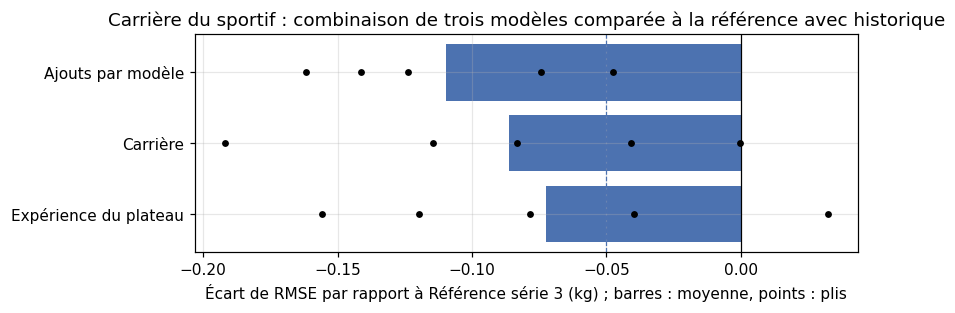

Les trois blocs satisfont le seuil : Variables finales


,oof_rmse,mean_delta,folds_better,keep
variant,,,,
Variables finales,76.876,-0.203,5,True
Ajouts par modèle,76.970,-0.110,5,True
Carrière,76.993,-0.086,5,True
Expérience du plateau,77.007,-0.072,4,True
Référence série 3,77.079,0.000,0,False


In [14]:
def show_round3():
    directory = ARTIFACTS / '02_feature_engineering' / CACHE_CAREER_ABLATION
    singles = {m: read_summary(directory / f'summary_single_{m}.csv') for m in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]}
    singles = {m: t for m, t in singles.items() if t is not None}
    if singles:
        print('ΔRMSE moyen par rapport à la référence avec historique (kg ; les ajouts propres au modèle ne changent pas LightGBM) :')
        display(pd.DataFrame({m: t['mean_delta'] for m, t in singles.items()}).reindex([BLOCK_ATHLETE_CAREER, BLOCK_MEET_EXPERIENCE, BLOCK_MODEL_SPECIFIC]).round(3))
    screen = read_summary(directory / 'summary_blend_screen.csv')
    print('Ensemble NNLS à trois modèles :')
    show(screen, ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'weights_lgb_xgb_cb'])
    plot_fold_deltas(screen, VARIANT_HISTORY_BASELINE, 'Carrière du sportif : combinaison de trois modèles comparée à la référence avec historique')
    print('Les trois blocs satisfont le seuil : ALL3')
    show(read_summary(directory / 'summary_blend_all3.csv'), ['oof_rmse', 'mean_delta', 'folds_better', 'keep'])


show_round3()

Carrière : −0.09 (5 plis sur 5). Expérience du plateau : −0.07 (4 sur 5). Ajouts par modèle : −0.11 (5 sur 5). **Les trois ensemble : −0.20 kg**, soit 76.876 pour la combinaison des trois modèles. Après cela, la plupart des résidus moyens par groupe sont sous 2 kg.

### 5.4 Quatrième série (expérience 14)

La référence est le jeu de variables final. La combinaison réunit LightGBM, XGBoost et le CatBoost à cible DOTS (notebook 03). Comme ces variables recoupent le lissage, on regarde aussi le score après lissage.

Le même bouton lance le contrôle des id (notebook 01) et les cibles alternatives (notebook 03).

In [15]:
if TRAIN[CACHE_PERFORMANCE_ABLATION]:
    ensure_training_env()
    # Statistiques de performance ; référence : variables finales par modèle ; ancien dossier : artifacts/feature_round4_v1
    OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / 'round4'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    SEEDS = [42, 7, 2024]                      # Chaque graine change les plis, l’early stopping et l’aléa du modèle
    FINAL_MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS, 'tabm']   # Modèles rapides en premier dans chaque pli
    FULL_REFIT = True                          # Refit des arbres sur tout le train
    REFIT_FACTOR = 1.2                         # Itérations de refit = moyenne CV × 1.2 (environ 39 % de données en plus)

    SCREEN_MODELS = ['lgb', 'xgb', 'cb_rel']        # Trois modèles de sélection, dont cb_rel
    TARGET_MODELS = ['cb_allo', 'cb_gl']            # Deux formules de force relative
    INNER_FEATURE_FOLDS = 5                         # Plis internes pour les variables issues des résultats
    # ---- Final features: Variables finales par modèle from experiment 10----
    _CAREER_FRAMES.clear()
    CAREER_VARIANTS[VARIANT_FINAL_FEATURES] = [BLOCK_ATHLETE_CAREER, BLOCK_MEET_EXPERIENCE, BLOCK_MODEL_SPECIFIC]
    FAMILY = {MODEL_LIGHTGBM: MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS: MODEL_LIGHTGBM, 'tabm': MODEL_LIGHTGBM, MODEL_XGBOOST: MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE: MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS: MODEL_CATBOOST_ABSOLUTE}
    FRAMES = {m: career_feature_frames(VARIANT_FINAL_FEATURES, FAMILY[m]) for m in FINAL_MODELS}
    for m, (Xtr_m, Xte_m, cats_m) in FRAMES.items():
        print(f'{m:9s} {Xtr_m.shape[1]} columns ({len(cats_m)} categorical), blocks: {feature_blocks_for_model(VARIANT_FINAL_FEATURES, FAMILY[m])}')


    from scipy.stats import spearmanr

    ids_all = pd.concat([train['id'], test['id']], ignore_index=True).to_numpy()
    order = np.argsort(ids_all)
    perm = np.random.default_rng(0).permutation(len(ids_all))
    checks = {'same_meet': meet.astype(str).to_numpy(), 'same_federation': both['Federation'].astype(str).to_numpy(),
              'same_year': both['MeetYear'].to_numpy(), 'same_country': both['Country'].astype(str).to_numpy()}
    rows = []
    for name, values in checks.items():
        by_id = float((values[order][1:] == values[order][:-1]).mean())
        random = float((values[perm][1:] == values[perm][:-1]).mean())
        rows.append({'adjacent_rows': name, 'sorted_by_id': by_id, 'random_order': random, 'ratio': by_id / max(random, 1e-12)})
    id_table = pd.DataFrame(rows).set_index('adjacent_rows')
    display(id_table.round(4))
    rho = float(spearmanr(ids_all, both['MeetYear'].to_numpy())[0])
    print(f'Spearman correlation of id and meet year: {rho:.4f}')
    ID_STRUCTURE = bool(id_table.loc['same_meet', 'ratio'] >= 1.5 or abs(rho) >= 0.1)
    print('Meet structure in id: ', ID_STRUCTURE, '→', 'include the ID variant' if ID_STRUCTURE else 'skip ID: no clear ordering signal')
    id_table.to_csv(OUTPUT_DIR / 'summary_id_check.csv')


    N_ALL = len(both)
    TEST_ROWS = np.arange(n_train, N_ALL)
    REL_ALL = np.full(N_ALL, np.nan)
    REL_ALL[:n_train] = y / dots_scale(train['Sex'], train['BodyweightKg'])    # Relative performance (DOTS score)
    TOTAL_ALL = np.full(N_ALL, np.nan)
    TOTAL_ALL[:n_train] = y
    BIRTH_ALL = pd.Series(np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int).to_numpy())
    YEAR_ALL = pd.Series(both['MeetYear'].astype(int).to_numpy())
    BW_ALL = both['BodyweightKg'].to_numpy(dtype='float64')
    VALID_ALL = (both['Country'] != 'Unknown').to_numpy()


    def text_key_all(columns):
        out = both[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + both[c].astype(str)
        return out.reset_index(drop=True)


    PFX_ALL = {MATCH_RESIDENCE: text_key_all(['Sex', 'Country', 'State']),
               MATCH_FEDERATION: text_key_all(['Sex', 'Country', 'State', 'Federation']),
               MATCH_EQUIPMENT: text_key_all(['Sex', 'Country', 'State', 'Federation', 'Equipment'])}
    KB_SHIFT = {k: {d: p + '|' + (BIRTH_ALL + d).astype(str) for d in (-1, 0, 1)} for k, p in PFX_ALL.items()}
    FEDERATION_BIRTHYEAR_KEYS = KB_SHIFT[MATCH_FEDERATION][0]
    FEDERATION_BIRTHYEAR_MEETYEAR_KEYS = FEDERATION_BIRTHYEAR_KEYS + '|' + YEAR_ALL.astype(str)
    DECAY_GAPS = range(-8, 9)
    KBY_SHIFT = {d: FEDERATION_BIRTHYEAR_KEYS + '|' + (YEAR_ALL + d).astype(str) for d in DECAY_GAPS}
    MEET_ALL = {'meet': meet.reset_index(drop=True).astype(str),
                'div': text_key_all(['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment'])}
    EXACT_ALL = pd.Series(pd.util.hash_pandas_object(both[RAW_FEATURES], index=False).to_numpy()).astype(str)
    CORE_ALL = pd.Series(pd.util.hash_pandas_object(both[CORE9], index=False).to_numpy()).astype(str)


    def agg(keys, values, ref, funcs=('sum', 'count', 'max')):
        frame = pd.DataFrame({'k': keys.iloc[ref].to_numpy(), 'v': values[ref]})
        return frame.groupby('k')['v'].agg(list(funcs))


    def lookup(table, column, keys, fill):
        return keys.map(table[column]).fillna(fill).to_numpy(dtype='float64')


    def athlete_block(ref, query):
        """ref: labeled training indices; query: indices in both, disjoint from ref."""
        cols, m = {}, len(query)
        for k in [MATCH_RESIDENCE, MATCH_FEDERATION, MATCH_EQUIPMENT]:
            table = agg(KB_SHIFT[k][0], REL_ALL, ref)
            bw_table = agg(KB_SHIFT[k][0], BW_ALL, ref, ('sum',))
            s, n, bws, mx = np.zeros(m), np.zeros(m), np.zeros(m), np.full(m, -np.inf)
            for d in (-1, 0, 1):                                       # Birth year +/-1
                kq = KB_SHIFT[k][d].iloc[query]
                s, n = s + lookup(table, 'sum', kq, 0), n + lookup(table, 'count', kq, 0)
                mx = np.maximum(mx, lookup(table, 'max', kq, -np.inf))
                bws = bws + lookup(bw_table, 'sum', kq, 0)
            has = n > 0
            cols[f'as_{k}_n'] = n
            cols[f'as_{k}_mean'] = np.where(has, s / np.maximum(n, 1), np.nan)
            cols[f'as_{k}_max'] = np.where(has, mx, np.nan)
            if k == MATCH_FEDERATION:
                cols['as_A1_bw_diff'] = np.where(has, BW_ALL[query] - bws / np.maximum(n, 1), np.nan)
        table = agg(FEDERATION_BIRTHYEAR_MEETYEAR_KEYS, REL_ALL, ref, ('sum', 'count'))          # Time decay and year difference (Résidence et fédération, exact birth year)
        ws, wn, gap_sum, gap_n, gap_min = np.zeros(m), np.zeros(m), np.zeros(m), np.zeros(m), np.full(m, np.inf)
        for d in DECAY_GAPS:
            kq = KBY_SHIFT[d].iloc[query]
            sd, nd = lookup(table, 'sum', kq, 0), lookup(table, 'count', kq, 0)
            w = float(np.exp(-abs(d) / 3.0))
            ws, wn = ws + w * sd, wn + w * nd
            gap_sum, gap_n = gap_sum + abs(d) * nd, gap_n + nd
            gap_min = np.where(nd > 0, np.minimum(gap_min, abs(d)), gap_min)
        cols['as_A1_decay'] = np.where(wn > 0, ws / np.maximum(wn, 1e-12), np.nan)
        cols['as_A1_gap_mean'] = np.where(gap_n > 0, gap_sum / np.maximum(gap_n, 1), np.nan)
        cols['as_A1_gap_min'] = np.where(np.isfinite(gap_min), gap_min, np.nan)
        cols['as_same_equipment_share'] = np.where(cols['as_A1_n'] > 0,
                                                   cols['as_A2_n'] / np.maximum(cols['as_A1_n'], 1), np.nan)
        frame = pd.DataFrame(cols)
        frame.loc[~VALID_ALL[query]] = np.nan                           # Disable athlete matching when country is unknown.
        for name, keys in [('tw_exact', EXACT_ALL), ('tw_core', CORE_ALL)]:
            t = agg(keys, TOTAL_ALL, ref, ('sum', 'count'))
            kq = keys.iloc[query]
            s, n = lookup(t, 'sum', kq, 0), lookup(t, 'count', kq, 0)
            frame[f'{name}_total'] = np.where(n > 0, s / np.maximum(n, 1), np.nan)
            frame[f'{name}_n'] = n
        return frame


    def meet_block(ref, query):
        cols = {}
        for name, keys in MEET_ALL.items():
            t = agg(keys, REL_ALL, ref)
            kq = keys.iloc[query]
            s, n, mx = lookup(t, 'sum', kq, 0), lookup(t, 'count', kq, 0), lookup(t, 'max', kq, np.nan)
            cols[f'ms_{name}_n'] = n
            cols[f'ms_{name}_mean'] = np.where(n > 0, s / np.maximum(n, 1), np.nan)
            cols[f'ms_{name}_max'] = np.where(n > 0, mx, np.nan)
        return pd.DataFrame(cols)


    BLOCK_FUNCS = {BLOCK_ATHLETE_PERFORMANCE: athlete_block, BLOCK_MEET_PERFORMANCE: meet_block}
    _FOLD_FEATS = {}


    def nested_features(block, fold):
        """(training features, test features): inner OOF for outer-training rows; full outer-training references for validation/test."""
        key = (block, fold)
        if key not in _FOLD_FEATS:
            fn = BLOCK_FUNCS[block]
            outer_train, outer_valid = np.flatnonzero(FOLD_IDS != fold), np.flatnonzero(FOLD_IDS == fold)
            parts = []
            inner = KFold(INNER_FEATURE_FOLDS, shuffle=True, random_state=100 + fold)
            for inner_ref, inner_query in inner.split(outer_train):
                part = fn(outer_train[inner_ref], outer_train[inner_query])
                part.index = outer_train[inner_query]
                parts.append(part)
            part = fn(outer_train, outer_valid)
            part.index = outer_valid
            parts.append(part)
            train_part = pd.concat(parts).sort_index()
            require(train_part.index.equals(pd.RangeIndex(n_train)), f'{block} fold {fold}: nested feature row mismatch')
            test_part = fn(outer_train, TEST_ROWS).reset_index(drop=True)
            _FOLD_FEATS[key] = (train_part, test_part)
        return _FOLD_FEATS[key]


    ID_TRAIN = pd.DataFrame({'row_id': train['id'].to_numpy(dtype='float64')})
    ID_TEST = pd.DataFrame({'row_id': test['id'].to_numpy(dtype='float64')})
    PERFORMANCE_VARIANTS = {VARIANT_FINAL_BASELINE: [], BLOCK_ATHLETE_PERFORMANCE: [BLOCK_ATHLETE_PERFORMANCE], BLOCK_MEET_PERFORMANCE: [BLOCK_MEET_PERFORMANCE]}
    if ID_STRUCTURE:
        PERFORMANCE_VARIANTS['ID'] = ['ID']
    FAMILY_OF = {MODEL_LIGHTGBM: MODEL_LIGHTGBM, MODEL_XGBOOST: MODEL_XGBOOST, MODEL_CATBOOST_DOTS: MODEL_CATBOOST_DOTS, MODEL_CATBOOST_ALLOMETRIC: MODEL_CATBOOST_DOTS, MODEL_CATBOOST_IPF_GL: MODEL_CATBOOST_DOTS}


    def performance_feature_frames(variant, model, fold):
        base_tr, base_te, _ = FRAMES[FAMILY_OF[model]]
        blocks = PERFORMANCE_VARIANTS[variant]
        extra_tr = [nested_features(b, fold)[0] for b in blocks if b in BLOCK_FUNCS]
        extra_te = [nested_features(b, fold)[1] for b in blocks if b in BLOCK_FUNCS]
        if 'ID' in blocks:
            extra_tr.append(ID_TRAIN)
            extra_te.append(ID_TEST)
        if not extra_tr:
            return base_tr, base_te
        return pd.concat([base_tr] + extra_tr, axis=1), pd.concat([base_te] + extra_te, axis=1)


    started = time.perf_counter()
    demo_tr, demo_te = nested_features(BLOCK_ATHLETE_PERFORMANCE, 1)
    print(f'AS, fold 1: {demo_tr.shape[1]} columns, elapsed  {time.perf_counter() - started:.0f}s')
    display(pd.DataFrame({'train_nonnull': demo_tr.notna().mean(), 'test_nonnull': demo_te.notna().mean(),
                          'train_mean': demo_tr.mean(), 'test_mean': demo_te.mean()}).round(3))
    corr = pd.Series({c: np.corrcoef(demo_tr[c].fillna(demo_tr[c].median()), y)[0, 1] for c in demo_tr.columns})
    print('Correlation with TotalKg (fold 1, nested OOF features for training rows): '); display(corr.round(3).sort_values())


    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)
    TABM_PARAMS = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0, num_emb_type='pwl')
    TABM_FALLBACK = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0)
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_LIGHTGBM_DOTS: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300, MODEL_CATBOOST_DOTS: 300}
    GBDT = [m for m in FINAL_MODELS if m != 'tabm']

    SCALE = dots_scale(train['Sex'], train['BodyweightKg'])           # dots_scale is defined in the experiment 09 features.
    SCALE_TEST = dots_scale(test['Sex'], test['BodyweightKg'])
    require(min(SCALE.min(), SCALE_TEST.min()) > 0.3, 'Invalid DOTS scale')

    X_NN, XT_NN, CATS_NN = FRAMES['tabm']
    NUM_NN = [c for c in X_NN.columns if c not in CATS_NN]
    NAN_NN = [c for c in NUM_NN if X_NN[c].isna().any() or XT_NN[c].isna().any()]


    def target_and_weight(model, rows):
        if model.endswith('_rel'):
            return y[rows] / SCALE[rows], SCALE[rows] ** 2       # Relative error * scale = error in kg
        return y[rows], None


    def gbdt_fit(model, seed, Xa, ya, wa, Xs=None, ys=None, ws=None, rounds=MAX_ROUNDS):
        """No early stopping when Xs is None. Return (model, best iteration)."""
        cats = FRAMES[model][2]
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=seed, n_jobs=-1, **LGB_PARAMS)
            if Xs is None:
                m.fit(Xa, ya, sample_weight=wa)
                return m, rounds
            m.fit(Xa, ya, sample_weight=wa, eval_set=[(Xs, ys)], eval_sample_weight=None if ws is None else [ws],
                  callbacks=[lgb.early_stopping(PATIENCE[model], verbose=False)])
            return m, int(m.best_iteration_ or rounds)
        if model == MODEL_XGBOOST:
            if Xs is None:
                m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, **XGB_PARAMS)
                m.fit(Xa, ya, verbose=False)
                return m, rounds
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            return m, int(m.best_iteration) + 1
        common = dict(iterations=rounds, loss_function='RMSE', eval_metric='RMSE', random_seed=seed, verbose=0,
                      task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
        if Xs is None:
            m = catboost.CatBoostRegressor(**common)
            m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa))
            return m, rounds
        m = catboost.CatBoostRegressor(od_type='Iter', od_wait=PATIENCE[model], **common)
        m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa),
              eval_set=catboost.Pool(Xs, ys, cat_features=cats, weight=ws), use_best_model=True)
        return m, int(m.get_best_iteration()) + 1


    def gbdt_predict(model, m, best, X):
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            return m.predict(X, num_iteration=best)
        if model == MODEL_XGBOOST:
            return m.predict(X, iteration_range=(0, best))
        return m.predict(X)


    def nn_frames(*frames):
        """Impute from the first fitting frame and add missingness flags; keep category dtype."""
        median = frames[0][NUM_NN].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_NN:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_NN] = z[NUM_NN].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def tabm_fit_predict(seed, a, s, v, Xt, overrides=None):
        require(TabM_D_Regressor is not None, f'pytabkit unavailable: {PYTABKIT_ERROR}')
        params = dict(TABM_PARAMS, random_state=seed, **(overrides or {}))
        unknown = set(params) - set(inspect.signature(TabM_D_Regressor.__init__).parameters)
        require(not unknown, f'TabM does not support parameters {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)
        mu, sd = y[a].mean(), y[a].std()
        m = TabM_D_Regressor(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_fold(model, seed, a, s, v, test_rows=None, rounds=MAX_ROUNDS, overrides=None):
        """a / s / v: inner fitting / early-stopping / outer validation indices. Return (validation predictions, test predictions, best iteration or None)."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if model == 'tabm':
            p_val, p_test = tabm_fit_predict(seed, a, s, v, Xt, overrides)
            return p_val, p_test, None
        ya, wa = target_and_weight(model, a)
        ys, ws = target_and_weight(model, s)
        if wa is not None:
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], ya, wa, Xtr.iloc[s], ys, ws, rounds)
        p_val, p_test = gbdt_predict(model, m, best, Xtr.iloc[v]), gbdt_predict(model, m, best, Xt)
        if model.endswith('_rel'):
            p_val, p_test = np.asarray(p_val) * SCALE[v], np.asarray(p_test) * scale_t
        return np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64'), best


    def fit_full(model, seed, rounds, test_rows=None):
        """Fit all rows for a fixed number of iterations; return test predictions."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        rows = np.arange(n_train)
        ya, wa = target_and_weight(model, rows)
        if wa is not None:
            wa = wa / wa.mean()
        m, _ = gbdt_fit(model, seed, Xtr, ya, wa, rounds=rounds)
        p_test = gbdt_predict(model, m, rounds, Xt)
        if model.endswith('_rel'):
            p_test = np.asarray(p_test) * scale_t
        return np.asarray(p_test, dtype='float64')


    def gl_scale(sex_values, equipment_values, bw_values):
        sex = np.asarray(sex_values).astype(str)
        equipped = ~np.isin(np.asarray(equipment_values).astype(str), ['Raw', 'Wraps'])
        bw = np.maximum(np.asarray(bw_values, dtype='float64'), 30.0)
        coef = {('M', False): (1199.72839, 1025.18162, 0.00921), ('M', True): (1236.25115, 1449.21864, 0.01644),
                ('F', False): (610.32796, 1045.59282, 0.03048), ('F', True): (758.63878, 949.31382, 0.02435)}

        def curve(s, e):
            a, b, c = coef[(s, e)]
            return a - b * np.exp(-c * bw)

        male = np.where(equipped, curve('M', True), curve('M', False))
        female = np.where(equipped, curve('F', True), curve('F', False))
        return np.where(sex == 'M', male, np.where(sex == 'F', female, 0.5 * (male + female))) / 100.0


    ALLO = (train['BodyweightKg'].to_numpy(dtype='float64') / 80.0) ** (2 / 3)
    ALLO_TEST = (test['BodyweightKg'].to_numpy(dtype='float64') / 80.0) ** (2 / 3)
    GL = gl_scale(train['Sex'], train['Equipment'], train['BodyweightKg'])
    GL_TEST = gl_scale(test['Sex'], test['Equipment'], test['BodyweightKg'])
    require(min(GL.min(), GL_TEST.min()) > 0 and min(ALLO.min(), ALLO_TEST.min()) > 0, 'Invalid performance scale')
    SCALE_OF = {MODEL_CATBOOST_DOTS: (SCALE, SCALE_TEST), MODEL_CATBOOST_ALLOMETRIC: (ALLO, ALLO_TEST), MODEL_CATBOOST_IPF_GL: (GL, GL_TEST)}
    for extra in TARGET_MODELS:
        FRAMES[extra] = FRAMES[MODEL_CATBOOST_DOTS]
        PATIENCE[extra] = PATIENCE[MODEL_CATBOOST_DOTS]


    def fit_matrix(model, Xtr, Xte, a, s, v, seed=SEED, rounds=MAX_ROUNDS, test_rows=None):
        """Fit the supplied features on a, stop on s; return (outer predictions, test predictions, best iteration)."""
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        if model in SCALE_OF:
            scale, scale_test = SCALE_OF[model]
            scale_t = scale_test if test_rows is None else scale_test[test_rows]
            ya, ys = y[a] / scale[a], y[s] / scale[s]
            norm = (scale[a] ** 2).mean()
            wa, ws = scale[a] ** 2 / norm, scale[s] ** 2 / norm
        else:
            ya, ys, wa, ws = y[a], y[s], None, None
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], ya, wa, Xtr.iloc[s], ys, ws, rounds)
        p_val = np.asarray(gbdt_predict(model, m, best, Xtr.iloc[v]), dtype='float64')
        p_test = np.asarray(gbdt_predict(model, m, best, Xt), dtype='float64')
        if model in SCALE_OF:
            p_val, p_test = p_val * scale[v], p_test * scale_t
        return p_val, p_test, best


    rng = np.random.default_rng(SEED)
    probe = rng.choice(np.flatnonzero(FOLD_IDS != 1), 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    checks = [(m, v) for v in PERFORMANCE_VARIANTS for m in SCREEN_MODELS] + [(m, VARIANT_FINAL_BASELINE) for m in TARGET_MODELS]
    for model, variant in checks:
        try:
            Xtr, Xte = performance_feature_frames(variant, model, 1)
            p_val, p_test, _ = fit_matrix(model, Xtr, Xte, pa, ps, pv, rounds=30, test_rows=np.arange(300))
            require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
            print(f'Smoke check passed: {model:8s} {variant:3s}({Xtr.shape[1]} columns)RMSE@30 iterations {rmse(y[pv], p_val):.1f}')
        except Exception as exc:
            failed[(model, variant)] = repr(exc)
            print(f'Smoke check failed, skipping: {model} {variant} → {exc!r}')
    require(not any(v == VARIANT_FINAL_BASELINE and m in SCREEN_MODELS for (m, v) in failed), 'Échec du contrôle des variables finales ; vérifier l’environnement')


    def run_one(model, variant, fold):
        stem = f'{model}__{variant}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            return json.loads(json_path.read_text(encoding='utf-8')), 'cache'
        Xtr, Xte = performance_feature_frames(variant, model, fold)
        fit_idx, valid_idx = np.flatnonzero(FOLD_IDS != fold), np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 07–13
        started = time.perf_counter()
        p_val, p_test, best = fit_matrix(model, Xtr, Xte, inner_fit, inner_stop, valid_idx)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        np.savez(npz_path, valid_idx=valid_idx, val=p_val, test=p_test)
        info = {'model': model, 'variant': variant, 'fold': fold, 'blocks': PERFORMANCE_VARIANTS[variant],
                'n_features': int(Xtr.shape[1]), 'best_iteration': best, 'rmse': rmse(y[valid_idx], p_val),
                'seconds': time.perf_counter() - started, 'gpu': GPU_NAME,
                'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info, f'{info["seconds"]:.0f}s'


    def run_variants(variants, models):
        for fold in range(1, N_FOLDS + 1):
            fold_started = time.perf_counter()
            for model in models:
                for variant in variants:
                    if (model, variant) in failed:
                        continue
                    info, how = run_one(model, variant, fold)
                    print(f'fold {fold}  {model:8s} {variant:4s}  RMSE {info["rmse"]:.3f}  '
                          f'best iteration {info["best_iteration"]:5d}  ({how})')
            print(f'—— fold {fold} finished; elapsed {(time.perf_counter() - fold_started) / 60:.1f} min')


    run_variants(list(PERFORMANCE_VARIANTS), SCREEN_MODELS)


    def load_oof(model, variant):
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = OUTPUT_DIR / f'{model}__{variant}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        return oof, test_pred


    def fold_rmse(pred):
        return pd.Series({k: rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)})


    def paired_table(preds, base=VARIANT_FINAL_BASELINE):
        base_folds = fold_rmse(preds[base])
        rows = []
        for name, pred in preds.items():
            delta = fold_rmse(pred) - base_folds
            rows.append({'variant': name, 'oof_rmse': rmse(y, pred), 'mean_delta': delta.mean(),
                         'folds_better': int((delta < 0).sum()), **{f'd_fold{k}': v for k, v in delta.items()}})
        table = pd.DataFrame(rows).set_index('variant')
        table['keep'] = (table['mean_delta'] <= KEEP_DELTA) & (table['folds_better'] >= 4)
        table.loc[base, 'keep'] = False
        return table.sort_values('oof_rmse')


    def blend_variant(variant, models=SCREEN_MODELS):
        loaded = [load_oof(m, variant) for m in models]
        if any(item is None for item in loaded):
            return None
        P_oof = np.column_stack([o for o, _ in loaded])
        P_test = np.column_stack([t for _, t in loaded])
        w, _ = nnls(P_oof, y)
        return {'oof': P_oof @ w, 'test': P_test @ w, 'weights': [round(float(x), 3) for x in w]}


    for model in SCREEN_MODELS:
        preds = {v: load_oof(model, v)[0] for v in PERFORMANCE_VARIANTS if load_oof(model, v) is not None}
        if VARIANT_FINAL_BASELINE in preds:
            print(f'\n=== {model}')
            display(paired_table(preds).round(3))
    BLENDS = {v: blend_variant(v) for v in PERFORMANCE_VARIANTS}
    BLENDS = {v: b for v, b in BLENDS.items() if b is not None}
    require(VARIANT_FINAL_BASELINE in BLENDS, 'Les résultats de la référence avec variables finales sont incomplets')
    blend_table = paired_table({v: b['oof'] for v, b in BLENDS.items()})
    blend_table['weights_lgb_xgb_cbrel'] = [str(BLENDS[v]['weights']) for v in blend_table.index]
    print('\n=== Three-model NNLS blend')
    display(blend_table.round(3))
    blend_table.to_csv(OUTPUT_DIR / 'summary_blend_screen.csv')
    KEPT4 = [v for v in PERFORMANCE_VARIANTS if v != VARIANT_FINAL_BASELINE and v in blend_table.index and bool(blend_table.loc[v, 'keep'])]
    print('Retained blocks: ', KEPT4 or 'none')
    if len(KEPT4) >= 2:
        PERFORMANCE_VARIANTS[VARIANT_PERFORMANCE_COMBINED] = [b for v in KEPT4 for b in PERFORMANCE_VARIANTS[v]]
        run_variants([VARIANT_PERFORMANCE_COMBINED], SCREEN_MODELS)
        BLENDS[VARIANT_PERFORMANCE_COMBINED] = blend_variant(VARIANT_PERFORMANCE_COMBINED)
        display(paired_table({v: BLENDS[v]['oof'] for v in [VARIANT_FINAL_BASELINE] + KEPT4 + [VARIANT_PERFORMANCE_COMBINED]}).round(3))
    FINAL4 = VARIANT_PERFORMANCE_COMBINED if VARIANT_PERFORMANCE_COMBINED in BLENDS else (KEPT4[0] if KEPT4 else None)
    if FINAL4 is None and len(blend_table) > 1:
        FINAL4 = blend_table.index[0] if blend_table.index[0] != VARIANT_FINAL_BASELINE else blend_table.index[1]
    print('Variante comparée à la référence avec variables finales après post-traitement : ', FINAL4)


    CORE = CORE9


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    def matching_group_statistics(train_keys, query_keys=None):
        table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
        if query_keys is None:                      # Training rows: leave one out
            keys = pd.Series(train_keys)
            n = keys.map(table['count']).to_numpy() - 1
            s = keys.map(table['sum']).to_numpy() - y
        else:                                       # Test rows: use all training rows
            keys = pd.Series(query_keys)
            n = keys.map(table['count']).fillna(0).to_numpy()
            s = keys.map(table['sum']).fillna(0).to_numpy()
        return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


    def matching_record_statistics(query_exact=None, query_core=None):
        n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
        n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        return level, np.where(level == 'exact', m_ex, m_co)


    def fit_alpha(mask, pred, mate):
        d = mate[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, mate, level, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    LEVEL, MATE = matching_record_statistics()
    T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
    HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
    TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


    def text_key(frame, columns):
        out = frame[columns[0]].astype(str)
        for c in columns[1:]:
            out = out + '|' + frame[c].astype(str)
        return out


    BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
    BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
    YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
    RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
              MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
              MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
    PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
    MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
    MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
    VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


    def sums(keys, values):
        table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        return table['sum'], table['count']


    def look(table, keys):
        s, n = table
        return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


    def exact_birthyear_residuals(k, r):
        ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
        table = sums(ktr, r)
        s, n = look(table, ktr)
        st, nt = look(table, kte)
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def nearby_birthyear_residuals(k, r):
        table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in (-1, 0, 1):
            a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
            s, n = s + a, n + b
            a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
            st, nt = st + a, nt + b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


    def temporal_residuals(k, r, tau=3.0, max_gap=8):
        base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
        base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
        table = sums(base_tr + YR_TR.astype(str), r)
        s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
        for d in range(-max_gap, max_gap + 1):
            w = float(np.exp(-abs(d) / tau))
            a, b = look(table, base_tr + (YR_TR + d).astype(str))
            s, n = s + w * a, n + w * b
            a, b = look(table, base_te + (YR_TE + d).astype(str))
            st, nt = st + w * a, nt + w * b
        return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


    def meet_residuals(r, lam=20.0):
        table = sums(MEET_TR, r)
        s, n = look(table, MEET_TR)
        st, nt = look(table, MEET_TE)
        return (s - r) / (n - 1 + lam), st / (nt + lam)


    def residual_neighborhood_features(r):
        cols_tr, cols_te = [], []
        for builder in (exact_birthyear_residuals, nearby_birthyear_residuals, temporal_residuals):
            for k in RESIDUAL_MATCH_COLUMNS:
                a, b = builder(k, r)
                cols_tr.append(a * VALID_TR)
                cols_te.append(b * VALID_TE)
        a, b = meet_residuals(r)
        cols_tr.append(a)
        cols_te.append(b)
        return np.column_stack(cols_tr), np.column_stack(cols_te)




    def stage2(oof, test_pred):
        alphas = {lv: fit_alpha(LEVEL == lv, oof, MATE) for lv in ['exact', 'core']}
        p1 = apply_matching_correction(oof, MATE, LEVEL, alphas)
        p1_cf = oof.copy()
        for h in (0, 1):
            a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), oof, MATE) for lv in ['exact', 'core']}
            m = HALF == h
            p1_cf[m] = apply_matching_correction(oof[m], MATE[m], LEVEL[m], a_h)
        corrected_residuals = y - p1
        F, FT = residual_neighborhood_features(corrected_residuals)
        p2_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            p2_cf[m] = p1_cf[m] + F[m] @ np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
        beta = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
        test_final = apply_matching_correction(test_pred, T_MATE, T_LEVEL, alphas) + FT @ beta
        return {'oof': rmse(y, oof), '+matched': rmse(y, p1_cf), SUMMARY_RESIDUAL_SMOOTHING: rmse(y, p2_cf),
                'fold_final': fold_rmse(p2_cf), 'test_final': test_final}


    net_rows, NET = [], {}
    for name in [v for v in [VARIANT_FINAL_BASELINE, FINAL4] if v is not None]:
        NET[name] = stage2(BLENDS[name]['oof'], BLENDS[name]['test'])
        net_rows.append({'variant': name, **{k: NET[name][k] for k in ['oof', '+matched', SUMMARY_RESIDUAL_SMOOTHING]}})
        path = OUTPUT_DIR / f'submission_{name}_blend3_stage2.csv'
        pd.DataFrame({'id': test['id'], TARGET: np.clip(NET[name]['test_final'], 0, None)}).to_csv(path, index=False)
        print('Saved', path.name)
    net_table = pd.DataFrame(net_rows).set_index('variant')
    display(net_table.round(3))
    if FINAL4 is not None:
        delta = NET[FINAL4]['fold_final'] - NET[VARIANT_FINAL_BASELINE]['fold_final']
        print(f'{FINAL4} par rapport à la référence avec variables finales après lissage : moyenne {delta.mean():+.3f}, {int((delta < 0).sum())}/5 folds improved')
    net_table.to_csv(OUTPUT_DIR / 'summary_net_after_stage2.csv')


    for model in TARGET_MODELS:
        if (model, VARIANT_FINAL_BASELINE) in failed:
            continue
        for fold in range(1, N_FOLDS + 1):
            info, how = run_one(model, VARIANT_FINAL_BASELINE, fold)
            print(f'fold {fold}  {model:8s}  RMSE {info["rmse"]:.3f}  best iteration {info["best_iteration"]}  ({how})')

    base_models = SCREEN_MODELS
    P_base = np.column_stack([load_oof(m, VARIANT_FINAL_BASELINE)[0] for m in base_models])


    def nested_nnls(oof_prediction_matrix):
        out = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            w, _ = nnls(oof_prediction_matrix[fit], y[fit])
            out[va] = oof_prediction_matrix[va] @ w
        return out


    base_nested = nested_nnls(P_base)
    rows = [{'model': m, 'oof': rmse(y, load_oof(m, VARIANT_FINAL_BASELINE)[0])} for m in base_models]
    for model in TARGET_MODELS:
        loaded = load_oof(model, VARIANT_FINAL_BASELINE)
        if loaded is None:
            continue
        nested = nested_nnls(np.column_stack([P_base, loaded[0]]))
        delta = fold_rmse(nested) - fold_rmse(base_nested)
        rows.append({'model': model, 'oof': rmse(y, loaded[0]),
                     'corr_with_cb_rel': float(np.corrcoef(loaded[0], load_oof(MODEL_CATBOOST_DOTS, VARIANT_FINAL_BASELINE)[0])[0, 1]),
                     'blend_delta_nested': rmse(y, nested) - rmse(y, base_nested), 'folds_better': int((delta < 0).sum())})
    target_table = pd.DataFrame(rows).set_index('model')
    print(f'Combinaison à trois modèles avec variables finales (poids croisés) : {rmse(y, base_nested):.3f}')
    display(target_table.round(3))
    target_table.to_csv(OUTPUT_DIR / 'summary_target_engineering.csv')
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN[CACHE_PERFORMANCE_ABLATION] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN[CACHE_PERFORMANCE_ABLATION] = False) : lecture des résultats dans artifacts/.


Ensemble NNLS : LightGBM, XGBoost, CatBoost DOTS :


,oof_rmse,mean_delta,folds_better,keep,weights_lgb_xgb_cbrel
variant,,,,,
Référence série 4,76.717,0.000,0,False,"[0.211, 0.214, 0.574]"
Niveau du sportif,76.856,0.139,0,False,"[0.384, 0.253, 0.365]"
Niveau de la compétition,77.233,0.516,0,False,"[0.524, 0.282, 0.197]"


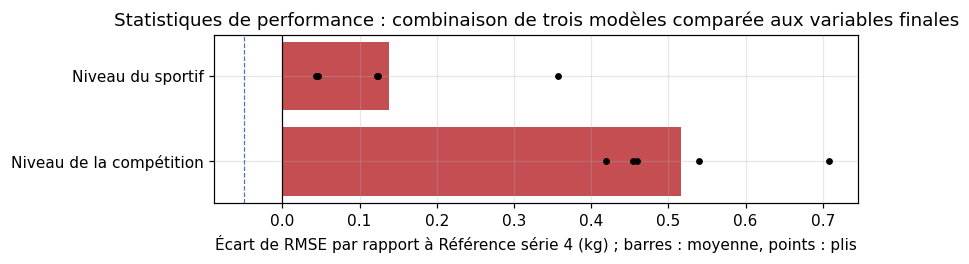

Après correction des correspondances et lissage combiné des résidus ; scores publics :


,oof,+matched,+S3,Public
variant,,,,
Référence série 4,76.717,76.493,76.361,76.592
Niveau du sportif,76.856,76.699,76.508,76.802


In [16]:
def show_round4():
    directory = ARTIFACTS / '02_feature_engineering' / CACHE_PERFORMANCE_ABLATION
    screen = read_summary(directory / 'summary_blend_screen.csv')
    print('Ensemble NNLS : LightGBM, XGBoost, cb_rel :')
    show(screen, ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'weights_lgb_xgb_cbrel'])
    plot_fold_deltas(screen, VARIANT_FINAL_BASELINE, 'Statistiques de performance : combinaison de trois modèles comparée aux variables finales')
    net = read_summary(directory / 'summary_net_after_stage2.csv')
    if net is not None:
        print('Après correction des correspondances et lissage combiné des résidus ; scores publics :')
        display(net.assign(Public=pd.Series({VARIANT_FINAL_BASELINE: 76.592, BLOCK_ATHLETE_PERFORMANCE: 76.802})).round(3))


show_round4()

Le niveau du sportif dégrade la RMSE de 0.14 kg et le niveau de la compétition de 0.52 kg, sans aucun pli amélioré. C'est pareil après lissage et au score public (76.802 contre 76.592). Deux explications possibles : à l'entraînement ces statistiques sont calculées sur 80 % des lignes seulement, donc pas tout à fait comme pour le test ; et elles sont bruitées, ce qui pousse au surapprentissage. La même information marche mieux dans le lissage, après les modèles.

## 6. Variables finales

| Modèles | Blocs | Colonnes |
|---|---|---:|
| LightGBM (kg et DOTS), TabM, HGB | départ + précision + déplacements + contexte + historique + carrière + expérience du plateau | 57 |
| XGBoost | les mêmes + contexte enrichi + DOTS + divisions | 78 |
| CatBoost (kg, DOTS, IPF GL) | les mêmes + contexte enrichi + identifiants | 73 |

Les notebooks 03 et 04 réutilisent le code des sections 1 à 3 quand un entraînement est lancé.